# Molecular Descriptors Calculation and Model Developments

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

file_path = '/content/drive/MyDrive/Neurotox/clean_sanitized_neurotox_data.csv'

df = pd.read_csv(file_path)
df

,SMILES,y
0,CCC1C(=O)OCC1Cc1cncn1C,-2.190332
1,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12,-2.017033
2,CN(C)CCCN1c2ccccc2Sc2ccccc21,-2.146128
3,C[N+](C)(C)CCCCCC[N+](C)(C)C,-1.792392
4,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,-1.792392
...,...,...
416,CC(CCC[N+](C)(C)C)c1ccco1,-1.477121
417,CN(CC[N+]1(C)CCCCC1)CC[N+]1(C)CCCCC1,-1.477121
418,C[Si](C)(COC(N)=O)c1ccccc1,-2.602060
419,C[Si](C)(CCCN)c1ccco1,-2.230449


In [3]:
#@title Compute the RDKit descriptors
!pip install -q rdkit
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors

# Create a list to store the descriptors
descs_list = []
valid_indices = []

# Define the input lists and dataframes from our loaded df
smiles_list = df['SMILES'].tolist()
df_sanitized = df

# Iterate over the SMILES, compute the descriptors, and append them to the list
# We will use all available descriptor calculators from RDKit Descriptors
calc_list = [desc[0] for desc in Descriptors._descList]

for idx, smiles in enumerate(smiles_list):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        mol_descs = {}
        # Add identifier columns
        mol_descs['SMILES'] = smiles
        mol_descs['y'] = df_sanitized.iloc[idx]['y']
        # Compute each descriptor
        for desc_name in calc_list:
            func = getattr(Descriptors, desc_name)
            try:
                mol_descs[desc_name] = func(mol)
            except Exception:
                mol_descs[desc_name] = np.nan
        descs_list.append(mol_descs)

# Convert the list of descriptors into a DataFrame
df_regression_with_descriptors = pd.DataFrame(descs_list)

# Keep this to check the resulting DataFrame
print(f"Computed descriptors shape: {df_regression_with_descriptors.shape}")
display(df_regression_with_descriptors.head())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 58.8 MB/s eta 0:00:00
Computed descriptors shape: (421, 219)


,SMILES,y,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,CCC1C(=O)OCC1Cc1cncn1C,-2.190332,11.384498,11.384498,0.037344,-0.037344,0.700091,25.600000,208.261,192.133,...,0,0,0,0,0,0,0,0,0,0
1,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12,-2.017033,12.423881,12.423881,0.062165,-0.593247,0.661809,37.454545,303.358,282.190,...,0,0,0,0,0,0,0,0,0,0
2,CN(C)CCCN1c2ccccc2Sc2ccccc21,-2.146128,2.462963,2.462963,1.062269,1.062269,0.828858,13.250000,284.428,264.268,...,0,0,0,0,0,0,0,0,0,0
3,C[N+](C)(C)CCCCCC[N+](C)(C)C,-1.792392,2.269884,2.269884,1.106481,1.106481,0.437226,13.285714,202.386,172.146,...,0,0,0,0,0,0,0,0,3,0
4,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,-1.792392,6.344297,6.344297,0.372348,0.372348,0.425097,17.400000,358.140,337.980,...,0,0,0,0,0,0,0,0,0,0


In [4]:
# Calculate total number of descriptors by subtracting identifier columns ('SMILES', 'y')
total_descriptors = df_regression_with_descriptors.shape[1] - 2
print(f"The total number of molecular descriptors is: {total_descriptors}")

The total number of molecular descriptors is: 217


# Descriptor cleaning

In [5]:
import numpy as np
import pandas as pd

# Make a copy of the dataframe to clean
df_cleaned_descs = df_regression_with_descriptors.copy()

# Identify descriptor columns (all columns except SMILES and y)
descriptor_cols = [col for col in df_cleaned_descs.columns if col not in ['SMILES', 'y']]

for col in descriptor_cols:
    # 1. Convert to numeric, turning strings or incompatible types into np.nan
    df_cleaned_descs[col] = pd.to_numeric(df_cleaned_descs[col], errors='coerce')

    # 2. Replace infinite values with np.nan
    df_cleaned_descs[col] = df_cleaned_descs[col].replace([np.inf, -np.inf], np.nan)

# 3. Filter out columns with more than 15% missing values
threshold = 0.15
missing_percentages = df_cleaned_descs[descriptor_cols].isnull().mean()
columns_to_keep = missing_percentages[missing_percentages <= threshold].index.tolist()

# Reassemble the dataframe with identifier columns and kept descriptors
df_cleaned_descs = df_cleaned_descs[['SMILES', 'y'] + columns_to_keep]

# Print summary of cleaning
initial_desc_count = len(descriptor_cols)
final_desc_count = len(columns_to_keep)
dropped_desc_count = initial_desc_count - final_desc_count

print(f"Initial number of descriptors: {initial_desc_count}")
print(f"Descriptors dropped (>15% missing): {dropped_desc_count}")
print(f"Final number of descriptors: {final_desc_count}")
print(f"Cleaned DataFrame shape: {df_cleaned_descs.shape}")

Initial number of descriptors: 217
Descriptors dropped (>15% missing): 0
Final number of descriptors: 217
Cleaned DataFrame shape: (421, 219)


In [6]:
from sklearn.model_selection import train_test_split

# Define seed and test split ratio
SEED = 2027
test_size = 0.3
PATH = '/content/drive/MyDrive/Neurotox/'

# Perform 70/30 train/test split
df_train, df_test = train_test_split(df_cleaned_descs, test_size=test_size, random_state=SEED)

# Save the splits to Google Drive
df_train.to_csv(PATH + 'PLC50_Train.csv', sep=';', index=False)
df_test.to_csv(PATH + 'PLC50_Test.csv', sep=';', index=False)

print(f"Dataset successfully split and saved to {PATH}.")
print(f"Training set shape: {df_train.shape}")
print(f"Test set shape: {df_test.shape}")

Dataset successfully split and saved to /content/drive/MyDrive/Neurotox/.
Training set shape: (294, 219)
Test set shape: (127, 219)


In [7]:
#@title Apply the imputation function to the training and test DataFrames
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer

def imputation_prediction(df_target, df_reference, desc_cols):
    """
    Imputes missing values in df_target based on the median values computed from df_reference.
    """
    # Create a copy to prevent modifying the original datasets
    df_imputed = df_target.copy()

    # Fit imputer on the reference dataset's descriptor columns
    imputer = SimpleImputer(strategy='median')
    imputer.fit(df_reference[desc_cols])

    # Transform the target dataset's descriptor columns
    df_imputed[desc_cols] = imputer.transform(df_target[desc_cols])
    return df_imputed

# Extract the descriptor column names and store them in a list
desc_columns = [col for col in df_train.columns if col not in ['SMILES', 'y']]

# Apply the imputation_prediction function
df_train_imputed = imputation_prediction(df_train, df_train, desc_columns)
df_test_imputed = imputation_prediction(df_test, df_train, desc_columns)

# Save the imputed DataFrames
df_train_imputed.to_csv(PATH + 'PLC50_Train_imputed.csv', sep=';', index=False)
df_test_imputed.to_csv(PATH + 'PLC50_Test_imputed.csv', sep=';', index=False)
print("Imputation completed and datasets saved successfully!")
print(f"Imputed Train Shape: {df_train_imputed.shape}")
print(f"Imputed Test Shape: {df_test_imputed.shape}")

Imputation completed and datasets saved successfully!
Imputed Train Shape: (294, 219)
Imputed Test Shape: (127, 219)


In [8]:
#@title Scale the descriptor values
# WRITE YOUR CODE HERE
# import the StandardScaler module from sklearn.preprocessing
from sklearn.preprocessing import StandardScaler

# instantiate the scaler class for StandardScaler
scaler = StandardScaler()

# Define non-descriptor columns
non_descriptor_cols = ["SMILES", "y"]

# Extract descriptor columns for training and test sets
desc_cols_train = [col for col in df_train_imputed.columns if col not in non_descriptor_cols]
desc_cols_test = [col for col in df_test_imputed.columns if col not in non_descriptor_cols]

# Create X (descriptors) and Y (response) dataframes for training and test sets
X_train = df_train_imputed[desc_cols_train]
Y_train = df_train_imputed['y']
SMILES_train = df_train_imputed['SMILES']

X_test = df_test_imputed[desc_cols_test]
Y_test = df_test_imputed['y']
SMILES_test = df_test_imputed['SMILES']

# fit to train data (IMPORTANT: Remember to use only the descriptor columns)
scaler.fit(X_train)

# transform train and test data (IMPORTANT: Remember to use only the descriptor columns)
X_train_scaled_array = scaler.transform(X_train)
X_test_scaled_array = scaler.transform(X_test)

# As in the case of imputation, scaler transformation returns a numpy array. So, we have to convert it again
# to a dataframe and concatenate with SMILES and y columns from the original dataframe
df_train_imputed_scaled = pd.DataFrame(X_train_scaled_array, columns=desc_cols_train, index=X_train.index)
df_train_imputed_scaled = pd.concat([SMILES_train, Y_train, df_train_imputed_scaled], axis=1)

# Now, apply the scaler also to the test dataframe and insert the SMILES and y columns
df_test_imputed_scaled = pd.DataFrame(X_test_scaled_array, columns=desc_cols_test, index=X_test.index)
df_test_imputed_scaled = pd.concat([SMILES_test, Y_test, df_test_imputed_scaled], axis=1)

In [9]:
#@title Removing infinite descriptors
import numpy as np
import pandas as pd

# Define non-descriptor columns
non_descriptor_cols = ["SMILES", "y"]

# Identify descriptor columns in train dataset
desc_cols_train = [col for col in df_train_imputed_scaled.columns if col not in non_descriptor_cols]

# Check which descriptor columns have only finite values in train set
finite_columns = [col for col in desc_cols_train if np.isfinite(df_train_imputed_scaled[col]).all()]

# Find the columns to drop (columns with non-finite values)
cols_to_drop_infinite = [col for col in desc_cols_train if col not in finite_columns]

# Drop the columns from both train and test scaled datasets
df_train_imputed_scaled = df_train_imputed_scaled.drop(columns=cols_to_drop_infinite)
df_test_imputed_scaled = df_test_imputed_scaled.drop(columns=cols_to_drop_infinite)

print(f"Number of descriptors removed due to infinite values: {len(cols_to_drop_infinite)}")
print(f"New train dataset shape: {df_train_imputed_scaled.shape}")
print(f"New test dataset shape: {df_test_imputed_scaled.shape}")

Number of descriptors removed due to infinite values: 0
New train dataset shape: (294, 219)
New test dataset shape: (127, 219)


In [10]:
#@title Removing missing descriptors
import pandas as pd
import numpy as np

# First we set up the desired threshold
missing_values_threshold = 0.00000000001

# Define non-descriptor columns
non_descriptor_cols = ["SMILES", "y"]

# Identify descriptor columns in train dataset
desc_cols_train = [col for col in df_train_imputed_scaled.columns if col not in non_descriptor_cols]

# Create a series containing the ratio of missing values in each descriptor
missing_ratio = df_train_imputed_scaled[desc_cols_train].isnull().sum() / len(df_train_imputed_scaled)

# Create an empty list as a holder for the columns with too many missing values
cols_to_drop_missing = []

# Iterate through the columns and, if they have a ratio of missing values higher than the selected threshold,
# append it to the list of columns to drop
for col in desc_cols_train:
    if missing_ratio[col] > missing_values_threshold:
        cols_to_drop_missing.append(col)

# Drop the selected descriptors from both train and test datasets
df_train_imputed_scaled = df_train_imputed_scaled.drop(columns=cols_to_drop_missing)
df_test_imputed_scaled = df_test_imputed_scaled.drop(columns=cols_to_drop_missing)

print(f"Number of descriptors removed due to missing values: {len(cols_to_drop_missing)}")
print(f"New train dataset shape: {df_train_imputed_scaled.shape}")
print(f"New test dataset shape: {df_test_imputed_scaled.shape}")

Number of descriptors removed due to missing values: 0
New train dataset shape: (294, 219)
New test dataset shape: (127, 219)


In [11]:
#@title Removing correlated descriptors
import numpy as np
import pandas as pd

#First we set up the desired correlation threshold
correlation_threshold = 0.9

# Define non-descriptor columns
non_descriptor_cols = ["SMILES", "y"]

# Identify descriptor columns in train dataset
desc_cols_train = [col for col in df_train_imputed_scaled.columns if col not in non_descriptor_cols]

#Compute a pairwise correlation of columns
correlation_matrix = df_train_imputed_scaled[desc_cols_train].corr().abs()

# Create a list to store the names of columns to be dropped
cols_to_drop_correlated = []

#Iterative through the correlation matrix to find highly correlated pairs
# Select upper triangle of correlation matrix
upper_tri = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))

# Find features with correlation greater than threshold
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > correlation_threshold)]

# Add the identified columns to the list of columns to drop
try:
    cols_to_drop_correlated.extend(to_drop)
except Exception:
    cols_to_drop_correlated = to_drop

# Ensure uniqueness of columns to drop
cols_to_drop_correlated = list(set(cols_to_drop_correlated))

#Drop the columns from both train and test scaled datasets
df_train_imputed_scaled = df_train_imputed_scaled.drop(columns=cols_to_drop_correlated)
df_test_imputed_scaled = df_test_imputed_scaled.drop(columns=cols_to_drop_correlated)

print(f"Number of descriptors removed due to high correlation: {len(cols_to_drop_correlated)}")
print(f"New train dataset shape: {df_train_imputed_scaled.shape}")
print(f"New test dataset shape: {df_test_imputed_scaled.shape}")

Number of descriptors removed due to high correlation: 48
New train dataset shape: (294, 171)
New test dataset shape: (127, 171)


In [12]:
#@title Select features using RFE with a linear regression estimator
#WRITE YOUR CODE HERE
#Import the module RFE from sklearn.feature_selection and the module LinearRegression from sklearn.linear_model
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

#Separate the descriptors array and the output variable
X_train = df_train.drop(columns=['SMILES', 'y'])
Y_train = df_train['y']

#Instantiate the estimator using the LinearRegression algorithm
estimator = LinearRegression()

#We need to stablish the number of features to select. We will start by 5 features.
n_features_to_select = 5

#Instantiate the RFE selector
rfe_selector = RFE(estimator=estimator, n_features_to_select=n_features_to_select, step=1)

#Fit the RFE selector to the training data
rfe_selector.fit(X_train, Y_train)

#Create a subset with the descriptors dataset
X_train_selected_rfe = X_train.loc[:, rfe_selector.get_support()]

#Join the selected descriptors to the output variable and SMILES column
df_train_rfe_linreg = pd.concat([df_train[['SMILES', 'y']], X_train_selected_rfe], axis=1)

#Now take the test dataframe and select only the descriptor columns of interest
X_test = df_test.drop(columns=['SMILES', 'y'])
X_test_selected_rfe = X_test.loc[:, rfe_selector.get_support()]
df_test_rfe_linreg = pd.concat([df_test[['SMILES', 'y']], X_test_selected_rfe], axis=1)

#Save both datasets as RAT_LC50_Train_RFE_linreg.csv and RAT_LC50_Test_RFE_linreg.csv files
df_train_rfe_linreg.to_csv(PATH + 'RAT_LC50_Train_RFE_linreg.csv', sep=';', index=False)
df_test_rfe_linreg.to_csv(PATH + 'RAT_LC50_Test_RFE_linreg.csv', sep=';', index=False)

print(f"Train RFE (Linear Regression) data saved to: {PATH + 'PLC50_Train_RFE_linreg.csv'}")
print(f"Test RFE (Linear Regression) data saved to: {PATH + 'PLC50_Test_RFE_linreg.csv'}")
print(f"Number of features selected: {n_features_to_select}")

Train RFE (Linear Regression) data saved to: /content/drive/MyDrive/Neurotox/PLC50_Train_RFE_linreg.csv
Test RFE (Linear Regression) data saved to: /content/drive/MyDrive/Neurotox/PLC50_Test_RFE_linreg.csv
Number of features selected: 5


In [13]:
#@title Select features using RFE with a decision tree estimator
#WRITE YOUR CODE HERE
#Import the module RFE from sklearn.feature_selection and the module DecisionTreeRegressor from sklearn.tree
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeRegressor

#Separate the descriptors array and the output variable
X_train = df_train.drop(columns=['SMILES', 'y'])
Y_train = df_train['y']

#Instantiate the estimator using the DecisionTreeRegressor algorithm
estimator = DecisionTreeRegressor(random_state=SEED)

#We need to stablish the number of features to select. We will start by 5 features.
n_features_to_select = 5

#Instantiate the RFE selector
rfe_selector = RFE(estimator=estimator, n_features_to_select=n_features_to_select, step=1)

#Fit the RFE selector to the training data
rfe_selector.fit(X_train, Y_train)

#Create a subset with the descriptors dataset
X_train_selected_rfe = X_train.loc[:, rfe_selector.get_support()]

#Join the selected descriptors to the output variable and SMILES column
df_train_rfe_dectreereg = pd.concat([df_train[['SMILES', 'y']], X_train_selected_rfe], axis=1)

#Now take the test dataframe and select only the descriptor columns of interest
X_test = df_test.drop(columns=['SMILES', 'y'])
X_test_selected_rfe = X_test.loc[:, rfe_selector.get_support()]
df_test_rfe_dectreereg = pd.concat([df_test[['SMILES', 'y']], X_test_selected_rfe], axis=1)

#Save both datasets as RAT_LC50_Train_RFE_dectreereg.csv and RAT_LC50_Test_RFE_dectreereg.csv files
df_train_rfe_dectreereg.to_csv(PATH + 'PLC50_Train_RFE_dectreereg.csv', sep=';', index=False)
df_test_rfe_dectreereg.to_csv(PATH + 'PLC50_Test_RFE_dectreereg.csv', sep=';', index=False)

print(f"Train RFE (Decision Tree) data saved to: {PATH + 'PLC50_Train_RFE_dectreereg.csv'}")
print(f"Test RFE (Decision Tree) data saved to: {PATH + 'PLC50_Test_RFE_dectreereg.csv'}")
print(f"Number of features selected: {n_features_to_select}")

Train RFE (Decision Tree) data saved to: /content/drive/MyDrive/Neurotox/PLC50_Train_RFE_dectreereg.csv
Test RFE (Decision Tree) data saved to: /content/drive/MyDrive/Neurotox/PLC50_Test_RFE_dectreereg.csv
Number of features selected: 5


In [14]:
#@title Select features using PI with a linear regression estimator

# Import required modules
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance # Use scikit-learn's permutation_importance
import pandas as pd

# Separate the descriptors array and the output variable
X_train = df_train.drop(columns=['SMILES', 'y'], errors='ignore')
Y_train = df_train['y']

# Instantiate the estimator using the LinearRegression algorithm
estimator = LinearRegression()

# Fit the estimator using the training data
estimator.fit(X_train, Y_train)

# Calculate permutation importance using sklearn.inspection.permutation_importance
# The n_jobs=-1 parameter uses all available processors for faster computation
result = permutation_importance(
    estimator,
    X_train,
    Y_train,
    n_repeats=10, # Number of times to permute a feature
    random_state=SEED,
    n_jobs=-1
)

# Get feature importances from the result
perm_importances_mean = result.importances_mean
perm_importances_std = result.importances_std

# Create a DataFrame with feature importances
dataframe_permutation = pd.DataFrame(
    {
        'feature': X_train.columns,
        'importance': perm_importances_mean,
        'std': perm_importances_std
    }
)

# Sort features by importance
dataframe_permutation_ordered = dataframe_permutation.sort_values(
    by='importance',
    ascending=False
).reset_index(drop=True)

# Select features that have a positive importance (or above a certain threshold if desired)
# For simplicity, we'll select features with importance > 0 for now, but a more robust threshold can be used.
# The original threshold was 0.01 based on eli5's SelectFromModel, but we need to adapt for sklearn's output.
# Let's consider a simple approach for demonstration, keeping all features with positive mean importance.
selected_features = dataframe_permutation_ordered[dataframe_permutation_ordered['importance'] > 0]['feature'].tolist()

# Display results
display(dataframe_permutation_ordered.head(10))

print("Number of original descriptors:", X_train.shape[1])
print("Number of selected descriptors:", len(selected_features))
print("Selected descriptors:")
print(selected_features)


,feature,importance,std
0,MolWt,1.988725e+06,132323.093204
1,ExactMolWt,1.644406e+06,109376.307110
2,HeavyAtomMolWt,2.621474e+04,1740.663806
3,MolMR,1.361266e+04,964.258603
4,Chi0,1.092729e+04,721.071460
5,NOCount,6.344953e+03,432.930395
6,VSA_EState2,4.156721e+03,221.806289
7,Chi1,2.911030e+03,193.819798
8,VSA_EState6,2.404251e+03,137.197345
9,LabuteASA,2.012738e+03,138.351386


Number of original descriptors: 217
Number of selected descriptors: 186
Selected descriptors:
['MolWt', 'ExactMolWt', 'HeavyAtomMolWt', 'MolMR', 'Chi0', 'NOCount', 'VSA_EState2', 'Chi1', 'VSA_EState6', 'LabuteASA', 'Chi0n', 'NumValenceElectrons', 'VSA_EState3', 'SlogP_VSA2', 'SlogP_VSA6', 'VSA_EState1', 'SlogP_VSA10', 'SMR_VSA7', 'PEOE_VSA14', 'fr_aniline', 'VSA_EState10', 'Chi1n', 'Chi0v', 'SlogP_VSA5', 'PEOE_VSA6', 'VSA_EState8', 'PEOE_VSA1', 'VSA_EState4', 'SlogP_VSA1', 'NumHAcceptors', 'VSA_EState7', 'fr_C_O', 'PEOE_VSA2', 'MolLogP', 'SMR_VSA6', 'SMR_VSA5', 'VSA_EState9', 'SMR_VSA10', 'PEOE_VSA8', 'PEOE_VSA7', 'NumHeteroatoms', 'PEOE_VSA9', 'EState_VSA7', 'NumAmideBonds', 'fr_amide', 'HallKierAlpha', 'PEOE_VSA3', 'EState_VSA8', 'SlogP_VSA12', 'fr_halogen', 'HeavyAtomCount', 'fr_C_O_noCOO', 'fr_ester', 'SlogP_VSA3', 'fr_quatN', 'EState_VSA4', 'EState_VSA5', 'SlogP_VSA4', 'Chi4v', 'Chi4n', 'SlogP_VSA11', 'Chi3n', 'SlogP_VSA7', 'Chi2v', 'VSA_EState5', 'fr_pyridine', 'PEOE_VSA10', 'ESt

<Axes: title={'center': 'Feature importances'}, ylabel='feature'>

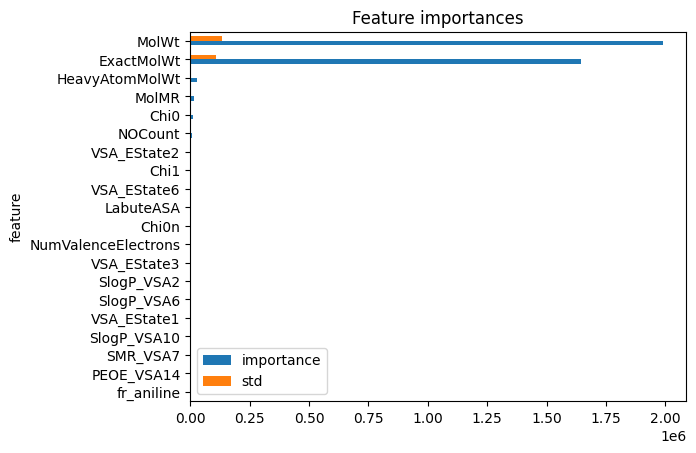

In [15]:
#@title Plotting the features importance
%matplotlib inline

import matplotlib.pyplot as plt

df_plot = dataframe_permutation_ordered.iloc[:20,:].sort_values('importance',ascending=True)

df_plot.plot(
    x="feature",
    kind = "barh",
    stacked = False,
    title = "Feature importances")

In [16]:
#@title Select the amount of desired descriptors
#WRITE YOUR CODE HERE
#Insert the number of features to select here
pi_n_feats_dt = 19 # Choosing 19 features, similar to the Linear Regression selection

# Fallback to the available permutation ordered dataframe if the DT-specific one isn't defined
if 'dataframe_permutation_ordered_dt' in globals():
    selected_features_dt_final = dataframe_permutation_ordered_dt['feature'].head(pi_n_feats_dt).tolist()
else:
    print("Using 'dataframe_permutation_ordered' as a fallback.")
    selected_features_dt_final = dataframe_permutation_ordered['feature'].head(pi_n_feats_dt).tolist()

# Separate the descriptors array and the output variable for X_train and X_test
X_train = df_train.drop(columns=['SMILES', 'y'], errors='ignore')
Y_train = df_train['y']
X_test = df_test.drop(columns=['SMILES', 'y'], errors='ignore')
Y_test = df_test['y']

# Create dataframes with only the selected features
X_train_selected_pi_dt = X_train[selected_features_dt_final]
X_test_selected_pi_dt = X_test[selected_features_dt_final]

#Join the selected descriptors to the output variable and SMILES column for train
df_train_pi_dectreereg = pd.concat([df_train[['SMILES', 'y']], X_train_selected_pi_dt], axis=1)

#Now take the test dataframe and select only the descriptor columns of interest
df_test_pi_dectreereg = pd.concat([df_test[['SMILES', 'y']], X_test_selected_pi_dt], axis=1)

#Save both datasets as RAT_LC50_Train_PI_dectreereg.csv and RAT_LC50_Test_PI_dectreereg.csv files
df_train_pi_dectreereg.to_csv(PATH + 'PLC50_Train_PI_dectreereg.csv', sep=';', index=False)
df_test_pi_dectreereg.to_csv(PATH + 'PLC50_Test_PI_dectreereg.csv', sep=';', index=False)

print(f"Train Permutation Importance (Decision Tree) data saved to: {PATH + 'PLC50_Train_PI_dectreereg.csv'}")
print(f"Test Permutation Importance (Decision Tree) data saved to: {PATH + 'PLC50_Test_PI_dectreereg.csv'}")
print(f"Number of features selected by Permutation Importance (Decision Tree): {pi_n_feats_dt}")

Using 'dataframe_permutation_ordered' as a fallback.
Train Permutation Importance (Decision Tree) data saved to: /content/drive/MyDrive/Neurotox/PLC50_Train_PI_dectreereg.csv
Test Permutation Importance (Decision Tree) data saved to: /content/drive/MyDrive/Neurotox/PLC50_Test_PI_dectreereg.csv
Number of features selected by Permutation Importance (Decision Tree): 19


In [17]:
#@title Apply the function to the train and test dataframes
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

combinations_algorithms_base_estimators = ['RFE_linreg', 'RFE_dectreereg','PI_linreg', 'PI_dectreereg']

# Loop through each combination of algorithm and base estimator
for combo in combinations_algorithms_base_estimators:
    # Define the actual file names based on the files created in your previous steps
    if combo == 'RFE_linreg':
        train_file_name_selected = PATH + 'PLC50_Train_RFE_linreg.csv'
        test_file_name_selected = PATH + 'PLC50_Test_RFE_linreg.csv'
    elif combo == 'RFE_dectreereg':
        train_file_name_selected = PATH + 'PLC50_Train_RFE_dectreereg.csv'
        test_file_name_selected = PATH + 'PLC50_Test_RFE_dectreereg.csv'
    elif combo == 'PI_linreg':
        train_file_name_selected = PATH + 'PLC50_Train_Selected_PI.csv'
        test_file_name_selected = PATH + 'PLC50_Test_Selected_PI.csv'
    elif combo == 'PI_dectreereg':
        train_file_name_selected = PATH + 'PLC50_Train_PI_dectreereg.csv'
        test_file_name_selected = PATH + 'PLC50_Test_PI_dectreereg.csv'

    # Load the selected feature datasets to get the list of selected columns
    try:
        df_train_selected_features = pd.read_csv(train_file_name_selected, sep=';')
        df_test_selected_features = pd.read_csv(test_file_name_selected, sep=';')
    except FileNotFoundError as e:
        print(f"Skipping {combo}: {e}")
        continue

    # Extract column names (excluding 'SMILES' and 'y') from the selected feature dataframes
    non_descriptor_cols = ["SMILES", "y"]
    selected_descriptor_cols = [col for col in df_train_selected_features.columns if col not in non_descriptor_cols]

    # Filter the original full train and test dataframes to keep only the selected descriptors + SMILES + y
    df_train_original_filtered = df_train[non_descriptor_cols + selected_descriptor_cols].copy()
    df_test_original_filtered = df_test[non_descriptor_cols + selected_descriptor_cols].copy()

    # Perform Imputation
    imputer = SimpleImputer(strategy='median')
    # Fit on training set descriptors
    imputer.fit(df_train_original_filtered[selected_descriptor_cols])

    # Transform both train and test
    df_train_original_filtered[selected_descriptor_cols] = imputer.transform(df_train_original_filtered[selected_descriptor_cols])
    df_test_original_filtered[selected_descriptor_cols] = imputer.transform(df_test_original_filtered[selected_descriptor_cols])

    # Perform Scaling
    scaler = StandardScaler()
    # Fit on training set descriptors
    scaler.fit(df_train_original_filtered[selected_descriptor_cols])

    # Transform both train and test
    df_train_original_filtered[selected_descriptor_cols] = scaler.transform(df_train_original_filtered[selected_descriptor_cols])
    df_test_original_filtered[selected_descriptor_cols] = scaler.transform(df_test_original_filtered[selected_descriptor_cols])

    # Save the resulting dataframes
    output_train_file = PATH + f'PLC50_Train_imputed_scaled_{combo}.csv'
    output_test_file = PATH + f'PLC50_Test_imputed_scaled_{combo}.csv'

    df_train_original_filtered.to_csv(output_train_file, sep=';', index=False)
    df_test_original_filtered.to_csv(output_test_file, sep=';', index=False)

    print(f"""Processed {combo}:
  Train imputed and scaled saved to: {output_train_file}
  Test imputed and scaled saved to: {output_test_file}
""")

Skipping RFE_linreg: [Errno 2] No such file or directory: '/content/drive/MyDrive/Neurotox/PLC50_Train_RFE_linreg.csv'
Processed RFE_dectreereg:
  Train imputed and scaled saved to: /content/drive/MyDrive/Neurotox/PLC50_Train_imputed_scaled_RFE_dectreereg.csv
  Test imputed and scaled saved to: /content/drive/MyDrive/Neurotox/PLC50_Test_imputed_scaled_RFE_dectreereg.csv

Processed PI_linreg:
  Train imputed and scaled saved to: /content/drive/MyDrive/Neurotox/PLC50_Train_imputed_scaled_PI_linreg.csv
  Test imputed and scaled saved to: /content/drive/MyDrive/Neurotox/PLC50_Test_imputed_scaled_PI_linreg.csv

Processed PI_dectreereg:
  Train imputed and scaled saved to: /content/drive/MyDrive/Neurotox/PLC50_Train_imputed_scaled_PI_dectreereg.csv
  Test imputed and scaled saved to: /content/drive/MyDrive/Neurotox/PLC50_Test_imputed_scaled_PI_dectreereg.csv



In [18]:
import pandas as pd

# Select one of the feature reduction algorithms and load the train dataframe generated with it.
# Using 'PI_dectreereg' as an example and corrected the filename prefix to PLC50_
train_df_path = PATH + 'PLC50_Train_imputed_scaled_PI_dectreereg.csv'
df_train_processed = pd.read_csv(train_df_path, sep=';')

# Split the dataframe in x (descriptors) and y (response value) variables
# Assuming 'SMILES' and 'y' are non-descriptor columns
X_train = df_train_processed.drop(columns=['SMILES', 'y'])
Y_train = df_train_processed['y']

print(f"Loaded training data from: {train_df_path}")
print(f"X_train shape: {X_train.shape}")
print(f"Y_train shape: {Y_train.shape}")

Loaded training data from: /content/drive/MyDrive/Neurotox/PLC50_Train_imputed_scaled_PI_dectreereg.csv
X_train shape: (294, 19)
Y_train shape: (294,)


In [19]:
#@title Instantiate (and configure) the estimator
# Import the LinearRegression module from sklearn.linear_model
from sklearn.linear_model import LinearRegression

# Instantiate the LinearRegression estimator
model = LinearRegression()

PRED

In [20]:
# Fit the estimator to the training data first
model.fit(X_train, Y_train)

# Now, perform predictions on the training data
Y_train_pred = model.predict(X_train)

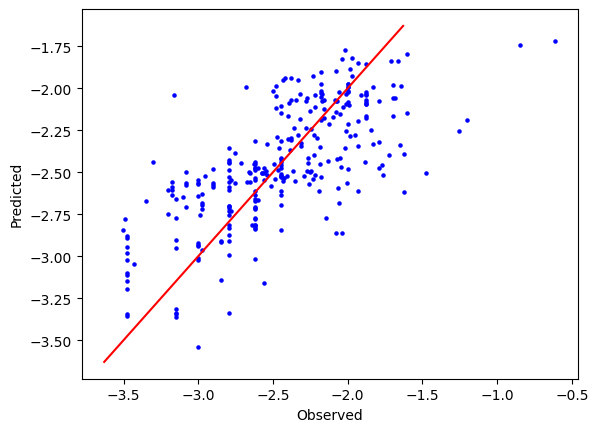

In [21]:
#@title Plotting the predicted vs the observed values
import matplotlib.pyplot as plt

def regression_plot(y_obs,y_pred):
    fig, ax = plt.subplots(1)
    ax.scatter(y_obs, y_pred, s=5, color="blue", label="original")
    ax.set_xlabel('Observed')
    ax.set_ylabel('Predicted')
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    lims = [max(x0, y0), min(x1, y1)]
    ax.plot(lims, lims, '-r')
    plt.show()

regression_plot(Y_train,Y_train_pred)

In [22]:
#@title Compute the $R^2$ value
# WRITE YOUR CODE HERE
# Import the numpy library
import numpy as np

# Calculate the average value of the response value. You can use the "mean" function from numpy
Y_train_mean = np.mean(Y_train)

# Calculate the numerator of the equation (SSRes)
SS_res = np.sum((Y_train - Y_train_pred)**2)

# Calculate the denominator of the equation (SSTot)
SS_tot = np.sum((Y_train - Y_train_mean)**2)

# Apply the equation to obtain the R2 value
R2_manual = 1 - (SS_res / SS_tot)
print(f"Manual R-squared: {R2_manual:.3f}")

Manual R-squared: 0.508


In [23]:
#@title Compute $R^2$, $EV$, $mse$ and $mae$ using the scikit-learn functions
# WRITE YOUR CODE HERE
# Import the modules r2_score, mean_squared_error, mean_absolute_error, explained_variance_score from sklearn.metrics
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, explained_variance_score

# Check the documentation of the previously imported modules and compute the four metrics
R2_sklearn = r2_score(Y_train, Y_train_pred)
EV_sklearn = explained_variance_score(Y_train, Y_train_pred)
MSE_sklearn = mean_squared_error(Y_train, Y_train_pred)
MAE_sklearn = mean_absolute_error(Y_train, Y_train_pred)

# Print the four metrics
print(f"R-squared (sklearn): {R2_sklearn:.3f}")
print(f"Explained Variance (sklearn): {EV_sklearn:.3f}")
print(f"Mean Squared Error (sklearn): {MSE_sklearn:.3f}")
print(f"Mean Absolute Error (sklearn): {MAE_sklearn:.3f}")

R-squared (sklearn): 0.508
Explained Variance (sklearn): 0.508
Mean Squared Error (sklearn): 0.120
Mean Absolute Error (sklearn): 0.263


In [24]:
#@title Function to check regression models

def check_regression_model(model,train_file,test_file,name,save=True):
    from sklearn.model_selection import cross_validate
    from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, explained_variance_score
    # First open the train and test files and save the dataframes with the descriptors and endpoint values
    train_dataset = pd.read_csv(train_file,sep=';')
    X_train = train_dataset.iloc[:, 2:]
    Y_train = train_dataset["y"]

    test_dataset = pd.read_csv(test_file,sep=';')
    X_test = test_dataset.iloc[:, 2:]
    Y_test = test_dataset["y"]

    #Fit the model (with the train only)
    model.fit(X_train,Y_train)

    #Predict the train and calculate the metrics
    Y_train_pred = model.predict(X_train)
    tr_R2=round(r2_score(Y_train,Y_train_pred),3)
    tr_mae=round(mean_absolute_error(Y_train,Y_train_pred),3)
    tr_mse=round(mean_squared_error(Y_train,Y_train_pred),3)
    tr_ev=round(explained_variance_score(Y_train,Y_train_pred),3)

    #Predict the test and calculate the metrics
    Y_test_pred = model.predict(X_test)
    ts_R2=round(r2_score(Y_test,Y_test_pred),3)
    ts_mae=round(mean_absolute_error(Y_test,Y_test_pred),3)
    ts_mse=round(mean_squared_error(Y_test,Y_test_pred),3)
    ts_ev=round(explained_variance_score(Y_test,Y_test_pred),3)

    #Perform cross_validation and save the test R-square only
    cv_results = cross_validate(model, X_train, Y_train,scoring='r2',return_train_score=True)
    cv_R2_mean=round(cv_results['test_score'].mean(),3)
    cv_R2_dev=round(cv_results['test_score'].std(),3)

    if save:
      results={}
      results.update({name:[tr_R2,tr_mae,tr_mse,tr_ev,
            ts_R2,ts_mae,ts_mse,ts_ev,
            cv_R2_mean,cv_R2_dev]})

    #Print results
    print('\t\tTRAIN\t\t\t\tTEST')
    print('R squared:\t',tr_R2,'\t\t\t\t',ts_R2)
    print('mae:\t',tr_mae,'\t\t\t\t',ts_mae)
    print('mse:\t',tr_mse,'\t\t\t\t',ts_mse)
    print('ev:\t',tr_ev,'\t\t\t\t',ts_ev)
    print('Cross validation R squared:',cv_R2_mean,'+/-',cv_R2_dev)

    return [tr_R2,tr_mae,tr_mse,tr_ev,
            ts_R2,ts_mae,ts_mse,ts_ev,
            cv_R2_mean,cv_R2_dev]






In [25]:
#@title Defining a function to generate a regression plot
import matplotlib.pyplot as plt

def regression_plot(y_obs,y_pred):
    fig, ax = plt.subplots(1)
    ax.scatter(y_obs, y_pred, s=5, color="blue", label="original")
    ax.set_xlabel('Observed')
    ax.set_ylabel('Predicted')
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    lims = [max(x0, y0), min(x1, y1)]
    ax.plot(lims, lims, '-r')
    plt.show()

In [26]:
from sklearn.ensemble import RandomForestRegressor

# Define the paths for the processed train and test sets (using the PI DecTree feature-selected dataset)
train_file_processed = PATH + 'PLC50_Train_imputed_scaled_PI_dectreereg.csv'
test_file_processed = PATH + 'PLC50_Test_imputed_scaled_PI_dectreereg.csv'

# Instantiate a Random Forest Regressor with tuned hyperparameters for QSAR modeling
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=SEED,
    max_depth=6,
    min_samples_split=5
)

# Train and evaluate the model using the helper function
print("Evaluating Random Forest Regressor on the selected dataset...")
results = check_regression_model(
    model=rf_model,
    train_file=train_file_processed,
    test_file=test_file_processed,
    name="RF_PI_dectreereg"
)

Evaluating Random Forest Regressor on the selected dataset...
		TRAIN				TEST
R squared:	 0.858 				 0.725
mae:	 0.136 				 0.199
mse:	 0.035 				 0.075
ev:	 0.858 				 0.726
Cross validation R squared: 0.606 +/- 0.1


--- Test Set Evaluation ---
R-squared (test): 0.480
Explained Variance (test): 0.483
Mean Squared Error (test): 0.143
Mean Absolute Error (test): 0.288
Generating regression plot for test set...


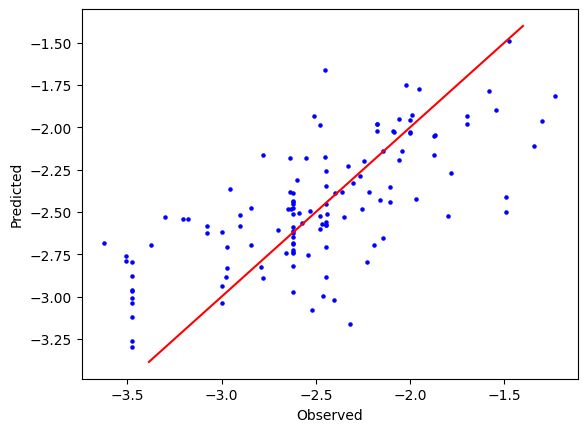

In [27]:
#@title Predict the response value of the test set
# WRITE YOUR CODE HERE
# Import the r2_score module from sklearn.metrics
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, explained_variance_score

# Load the corresponding dataframe with the test set from the same feature reduction algorithm.
test_df_path = PATH + 'PLC50_Test_imputed_scaled_PI_dectreereg.csv'
df_test_processed = pd.read_csv(test_df_path, sep=';')

# Split the test dataframe in x (descriptors) and y (response value) variables
X_test = df_test_processed.drop(columns=['SMILES', 'y'])
Y_test = df_test_processed['y']

# Predict the test response values and store them in the Y_test_pred variable
Y_test_pred = model.predict(X_test)

# Use the regression_plot and the r2_score functions to visualize how good is the model
print("--- Test Set Evaluation ---")
r2_test = r2_score(Y_test, Y_test_pred)
mae_test = mean_absolute_error(Y_test, Y_test_pred)
mse_test = mean_squared_error(Y_test, Y_test_pred)
ev_test = explained_variance_score(Y_test, Y_test_pred)

print(f"R-squared (test): {r2_test:.3f}")
print(f"Explained Variance (test): {ev_test:.3f}")
print(f"Mean Squared Error (test): {mse_test:.3f}")
print(f"Mean Absolute Error (test): {mae_test:.3f}")

print("Generating regression plot for test set...")
regression_plot(Y_test, Y_test_pred)

Training R-squared (fit_intercept=False): -24.045
Generating regression plot for training set (fit_intercept=False)...


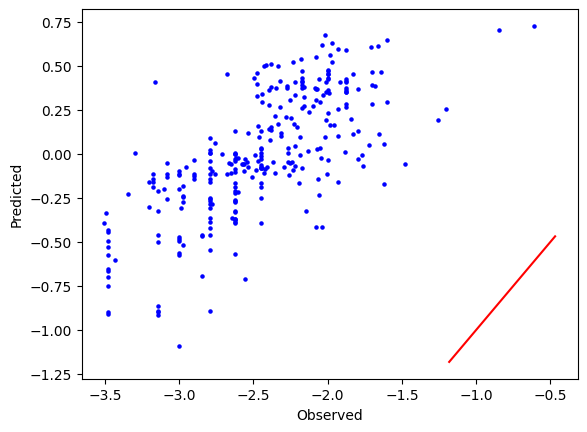

Test R-squared (fit_intercept=False): -21.938
Generating regression plot for test set (fit_intercept=False)...


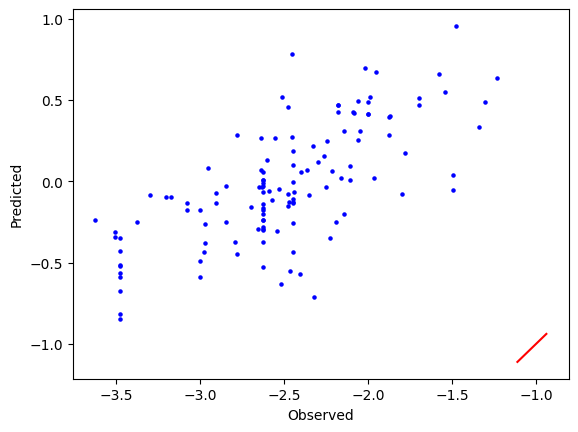

In [28]:
#@title Modification of hyperparameters for the linear regression algorithm
# WRITE YOUR CODE HERE
# Instantiate the LinearRegression estimator using the hyperparameter that select if the intercept is assumed to be 0 or if is calculated,
# and setting it up to the non-default value
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def regression_plot(y_obs,y_pred):
    fig, ax = plt.subplots(1)
    ax.scatter(y_obs, y_pred, s=5, color="blue", label="original")
    ax.set_xlabel('Observed')
    ax.set_ylabel('Predicted')
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    lims = [max(x0, y0), min(x1, y1)]
    ax.plot(lims, lims, '-r')
    plt.show()

# Instantiate the LinearRegression estimator with fit_intercept=False
model_no_intercept = LinearRegression(fit_intercept=False)

# Load again the train dataframe and split it in x (descriptors) and y (response value) variables.
train_df_path = PATH + 'PLC50_Train_imputed_scaled_PI_dectreereg.csv'
df_train_processed = pd.read_csv(train_df_path, sep=';')
X_train = df_train_processed.drop(columns=['SMILES', 'y'])
Y_train = df_train_processed['y']

# Fit the model with the train data and then, predict the response values of the train data with the newly generated model.
model_no_intercept.fit(X_train, Y_train)
Y_train_pred_no_intercept = model_no_intercept.predict(X_train)

# Use the plot and r2 score to evaluate the model for training set
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, explained_variance_score
R2_train_no_intercept = r2_score(Y_train, Y_train_pred_no_intercept)
print(f"Training R-squared (fit_intercept=False): {R2_train_no_intercept:.3f}")
print("Generating regression plot for training set (fit_intercept=False)...")
regression_plot(Y_train, Y_train_pred_no_intercept)

# Load the test data and predict
test_df_path = PATH + 'PLC50_Test_imputed_scaled_PI_dectreereg.csv'
df_test_processed = pd.read_csv(test_df_path, sep=';')
X_test = df_test_processed.drop(columns=['SMILES', 'y'])
Y_test = df_test_processed['y']
Y_test_pred_no_intercept = model_no_intercept.predict(X_test)

R2_test_no_intercept = r2_score(Y_test, Y_test_pred_no_intercept)
print(f"Test R-squared (fit_intercept=False): {R2_test_no_intercept:.3f}")
print("Generating regression plot for test set (fit_intercept=False)...")
regression_plot(Y_test, Y_test_pred_no_intercept)


--- SVR Model Evaluation (Training Set) ---
R-squared (SVR): 0.780
Generating regression plot for SVR training set...


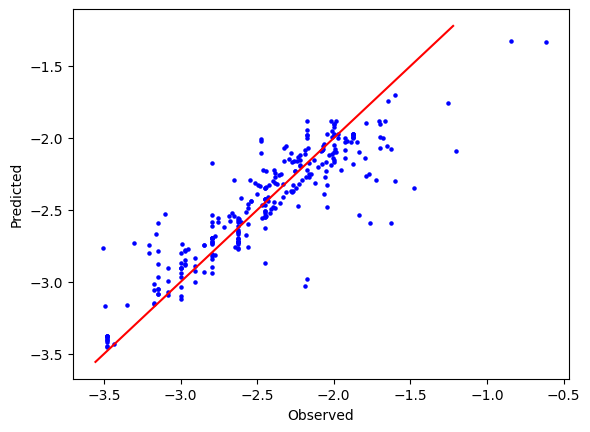

In [29]:
#@title Using another algorithm: Support Vector Machine Regressor
# WRITE YOUR CODE HERE
# Import the SVR module from sklearn.svm
from sklearn.svm import SVR
import pandas as pd

# Load the train dataframe and split it in x (descriptors) and y (response value) variables.
# Corrected the filename prefix to PLC50_ to resolve the FileNotFoundError
train_df_path = PATH + 'PLC50_Train_imputed_scaled_PI_dectreereg.csv'
df_train_processed = pd.read_csv(train_df_path, sep=';')
X_train = df_train_processed.drop(columns=['SMILES', 'y'])
Y_train = df_train_processed['y']

# Instantiate the SVR estimator, fit the model with the train data and predict the response values of the train data.
model_svr = SVR()
model_svr.fit(X_train, Y_train)
Y_train_pred_svr = model_svr.predict(X_train)

# Use the plot and r2 score to evaluate the model
from sklearn.metrics import r2_score

print("--- SVR Model Evaluation (Training Set) ---")
R2_svr = r2_score(Y_train, Y_train_pred_svr)
print(f"R-squared (SVR): {R2_svr:.3f}")

print("Generating regression plot for SVR training set...")
regression_plot(Y_train, Y_train_pred_svr)

--- SVR Model Evaluation (Training Set with C=10) ---
R-squared (SVR with C=10): 0.905
Generating regression plot for SVR training set (C=10)...


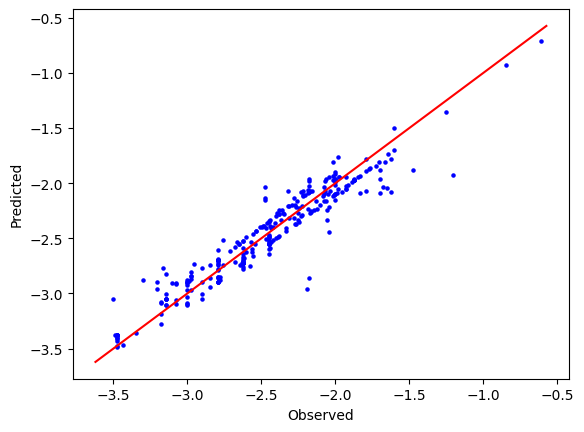

In [30]:
#@title Modification of hyperparameters for the SVR algorithm
# Import necessary libraries
from sklearn.svm import SVR
import pandas as pd
from sklearn.metrics import r2_score

# Load the train dataframe and split it in x (descriptors) and y (response value) variables.
# We can reuse the already loaded df_train_processed from the previous model development section
train_df_path = PATH + 'PLC50_Train_imputed_scaled_PI_dectreereg.csv'
df_train_processed = pd.read_csv(train_df_path, sep=';')
X_train = df_train_processed.drop(columns=['SMILES', 'y'])
Y_train = df_train_processed['y']

# Instantiate the SVR estimator with the C hyperparameter set it to 10, fit the model with the train data and predict the response values of the train data.
model_svr_c10 = SVR(C=10) # Set C to 10
model_svr_c10.fit(X_train, Y_train)
Y_train_pred_svr_c10 = model_svr_c10.predict(X_train)

# Use the plot and r2 score to evaluate the model
print("--- SVR Model Evaluation (Training Set with C=10) ---")
R2_svr_c10 = r2_score(Y_train, Y_train_pred_svr_c10)
print(f"R-squared (SVR with C=10): {R2_svr_c10:.3f}")

print("Generating regression plot for SVR training set (C=10)...")
regression_plot(Y_train, Y_train_pred_svr_c10)

--- MLPRegressor Model Evaluation (Training Set) ---
R-squared (MLPRegressor): 0.846
Generating regression plot for MLPRegressor training set...


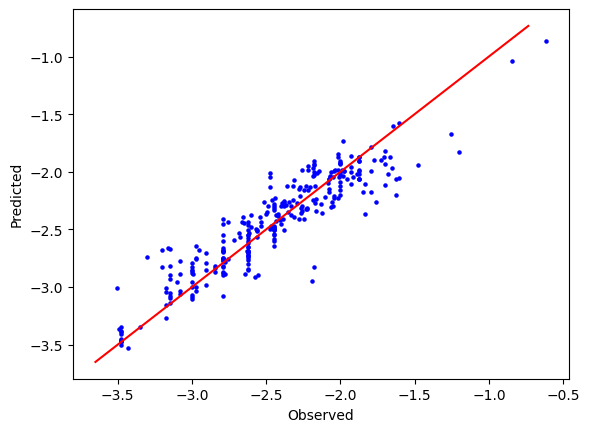

In [31]:
#@title Using another algorithm: Neural Networks
# Import the MLPRegressor module from sklearn.neural_network
from sklearn.neural_network import MLPRegressor
import pandas as pd
from sklearn.metrics import r2_score

# Load the train dataframe and split it in x (descriptors) and y (response value) variables.
# We can reuse the already loaded df_train_processed from the previous model development section
# Ensure X_train and Y_train are defined from the PI_dectreereg processed data
train_df_path = PATH + 'PLC50_Train_imputed_scaled_PI_dectreereg.csv'
df_train_processed = pd.read_csv(train_df_path, sep=';')
X_train = df_train_processed.drop(columns=['SMILES', 'y'])
Y_train = df_train_processed['y']

# Instantiate the MLPRegressor estimator, fit the model with the train data and predict the response values of the train data.
# Using default parameters for now, which can be tuned later.
model_mlp = MLPRegressor(random_state=SEED, max_iter=1000) # Added max_iter to avoid convergence warning
model_mlp.fit(X_train, Y_train)
Y_train_pred_mlp = model_mlp.predict(X_train)

# Use the plot and r2 score to evaluate the model
print("--- MLPRegressor Model Evaluation (Training Set) ---")
R2_mlp = r2_score(Y_train, Y_train_pred_mlp)
print(f"R-squared (MLPRegressor): {R2_mlp:.3f}")

print("Generating regression plot for MLPRegressor training set...")
regression_plot(Y_train, Y_train_pred_mlp)


--- ExtraTreesRegressor Model Evaluation (Training Set) ---
R-squared (ExtraTreesRegressor): 1.000
Generating regression plot for ExtraTreesRegressor training set...


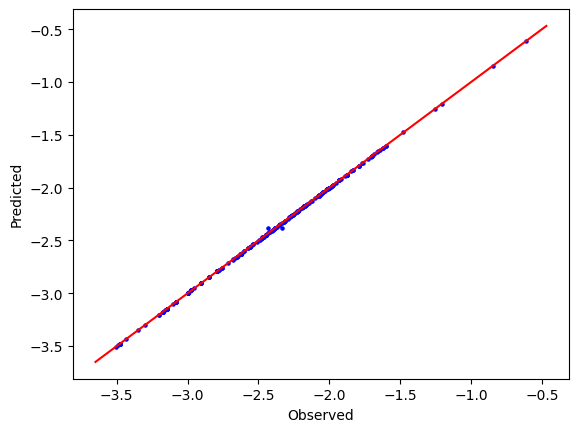

In [32]:
#@title Using another algorithm: ExtraTrees Regressor
# Import the ExtraTreesRegressor module from sklearn.ensemble
from sklearn.ensemble import ExtraTreesRegressor
import pandas as pd
from sklearn.metrics import r2_score

# Load the train dataframe and split it in x (descriptors) and y (response value) variables.
# We can reuse the already loaded df_train_processed from the previous model development section
# Ensure X_train and Y_train are defined from the PI_dectreereg processed data
train_df_path = PATH + 'PLC50_Train_imputed_scaled_PI_dectreereg.csv'
df_train_processed = pd.read_csv(train_df_path, sep=';')
X_train = df_train_processed.drop(columns=['SMILES', 'y'])
Y_train = df_train_processed['y']

# Instantiate the ExtraTreesRegressor estimator with 40 trees in the forest, fit the model with the train data and predict the response values of the train data.
model_et = ExtraTreesRegressor(n_estimators=40, random_state=SEED) # Added random_state for reproducibility
model_et.fit(X_train, Y_train)
Y_train_pred_et = model_et.predict(X_train)

# Use the plot and r2 score to evaluate the model
print("--- ExtraTreesRegressor Model Evaluation (Training Set) ---")
R2_et = r2_score(Y_train, Y_train_pred_et)
print(f"R-squared (ExtraTreesRegressor): {R2_et:.3f}")

print("Generating regression plot for ExtraTreesRegressor training set...")
regression_plot(Y_train, Y_train_pred_et)


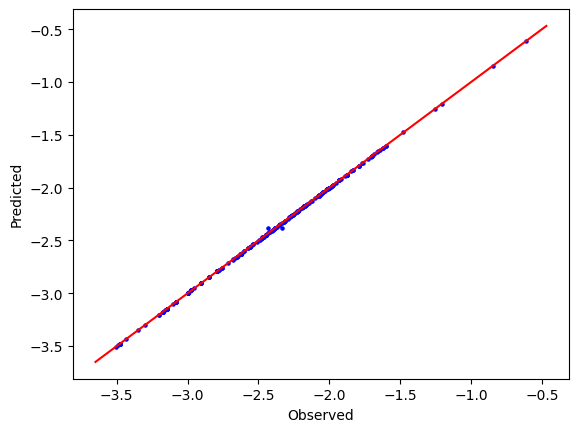

R-squared (ExtraTrees): 1.000


In [33]:
from sklearn.ensemble import ExtraTreesRegressor
import pandas as pd
from sklearn.metrics import r2_score

# Corrected path by prepending the PATH variable
train_dataset = pd.read_csv(PATH + 'PLC50_Train_PI_dectreereg.csv', sep=';')

X_train = train_dataset.iloc[:, 2:]
Y_train = train_dataset["y"]

model = ExtraTreesRegressor(n_estimators=40, random_state=SEED)
model.fit(X_train, Y_train)

Y_train_pred = model.predict(X_train)

regression_plot(Y_train, Y_train_pred)
print(f"R-squared (ExtraTrees): {r2_score(Y_train, Y_train_pred):.3f}")

In [34]:
Y_test_pred = model.predict(X_test)

print("Test R²:", round(r2_score(Y_test, Y_test_pred), 3))

Test R²: 0.016


In [35]:
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.ensemble import ExtraTreesRegressor

# Define the hyperparameter search space for Extra Trees
param_grid = {
    'n_estimators': [10, 20, 40, 50, 100, 150],
    'max_depth': [None, 3, 5, 8, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [1.0, 'sqrt', 'log2']
}

# Setup cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

# Instantiate the base ExtraTreesRegressor
model_et = ExtraTreesRegressor(random_state=SEED)

# Set up randomized search
search = RandomizedSearchCV(
    estimator=model_et,
    param_distributions=param_grid,
    n_iter=30,
    cv=cv,
    scoring='r2',
    random_state=SEED,
    n_jobs=-1
)

search.fit(X_train, Y_train)

print("Best parameters:", search.best_params_)
print("Best CV R²:", round(search.best_score_, 3))

Best parameters: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 10}
Best CV R²: 0.67


Evaluating final optimized ExtraTreesRegressor...
		TRAIN				TEST
R squared:	 0.971 				 0.76
mae:	 0.055 				 0.184
mse:	 0.007 				 0.066
ev:	 0.971 				 0.761
Cross validation R squared: 0.684 +/- 0.087
Generating regression plot for the optimized model on the Test Set...


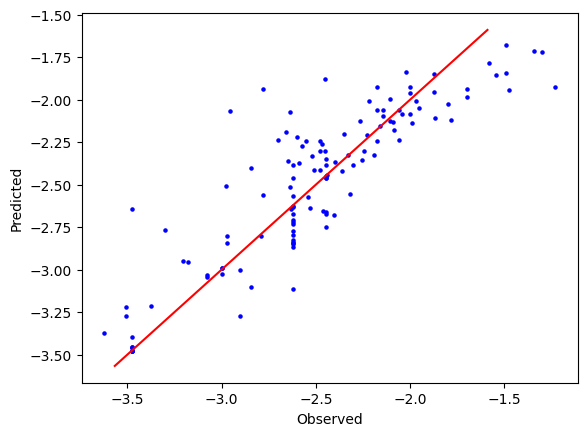

In [36]:
from sklearn.ensemble import ExtraTreesRegressor
import pandas as pd
from sklearn.metrics import r2_score

# Instantiate the optimized ExtraTreesRegressor with the best hyperparameters found
best_params = search.best_params_
optimized_model = ExtraTreesRegressor(**best_params, random_state=SEED)

# Train and evaluate using the helper function
print("Evaluating final optimized ExtraTreesRegressor...")
results = check_regression_model(
    model=optimized_model,
    train_file=train_file_processed,
    test_file=test_file_processed,
    name="ExtraTrees_Optimized"
)

# Plot the final test set predictions
Y_test_pred_opt = optimized_model.predict(X_test)
print("Generating regression plot for the optimized model on the Test Set...")
regression_plot(Y_test, Y_test_pred_opt)

Random forest

In [37]:

from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

# Define the hyperparameter search space for Random Forest
param_grid_rf = {
    'n_estimators': [10, 20, 40, 50, 100, 150],
    'max_depth': [None, 3, 5, 8, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [1.0, 'sqrt', 'log2']
}

# Setup cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Instantiate the Random Forest model
model_rf = RandomForestRegressor(random_state=42)

# Set up randomized search
search_rf = RandomizedSearchCV(
    estimator=model_rf,
    param_distributions=param_grid_rf,
    n_iter=30,
    cv=cv,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

# Fit using training data only
search_rf.fit(X_train, Y_train)

# Print results
print("Best RF parameters:", search_rf.best_params_)
print("Best RF CV R²:", round(search_rf.best_score_, 3))


Best RF parameters: {'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': None}
Best RF CV R²: 0.658


Evaluating final optimized Random Forest model...
		TRAIN				TEST
R squared:	 0.925 				 0.749
mae:	 0.089 				 0.193
mse:	 0.018 				 0.069
ev:	 0.925 				 0.75
Cross validation R squared: 0.656 +/- 0.067
Generating regression plot for the optimized RF model on the Test Set...


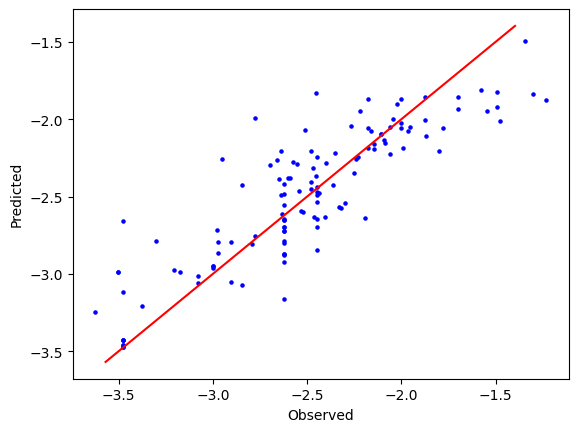

In [38]:
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

# Instantiate the optimized Random Forest using the best parameters from our search
best_rf_params = search_rf.best_params_
optimized_rf_model = RandomForestRegressor(**best_rf_params, random_state=42)

# Train and evaluate using the helper function
print("Evaluating final optimized Random Forest model...")
rf_results = check_regression_model(
    model=optimized_rf_model,
    train_file=train_file_processed,
    test_file=test_file_processed,
    name="RF_Optimized"
)

# Predict and plot the final test set predictions
Y_test_pred_rf = optimized_rf_model.predict(X_test)
print("Generating regression plot for the optimized RF model on the Test Set...")
regression_plot(Y_test, Y_test_pred_rf)

In [39]:
import seaborn as sns
import pandas as pd
from sklearn.svm import SVR
from sklearn.metrics import r2_score

# Load the train and test dataframes and split it in x (descriptors) and y (response value) variables, as X_train, Y_train, X_test, Y_test.
train_df_path = PATH + 'PLC50_Train_imputed_scaled_PI_dectreereg.csv'
test_df_path = PATH + 'PLC50_Test_imputed_scaled_PI_dectreereg.csv'

df_train_processed = pd.read_csv(train_df_path, sep=';')
df_test_processed = pd.read_csv(test_df_path, sep=';')

X_train = df_train_processed.drop(columns=['SMILES', 'y'])
Y_train = df_train_processed['y']

X_test = df_test_processed.drop(columns=['SMILES', 'y'])
Y_test = df_test_processed['y']

# Create three empty list as holders for the C values, the R squares for the train set prediction, and the R squares for the test set prediction
# as c_values, rsqs_train and rsqs_test
c_values = []
rsqs_train = []
rsqs_test = []

# Iterate through a range of C values from 1 to 50
for c in range(1, 51):
    # For each C value instantiate the SVR estimator with the corresponding C value
    model_svr = SVR(C=c)

    # Fit the model with the train data
    model_svr.fit(X_train, Y_train)

    # Then, predict the response values for both, the train and the test set.
    # Store the predictions as Y_train_pred and Y_test_pred
    Y_train_pred = model_svr.predict(X_train)
    Y_test_pred = model_svr.predict(X_test)

    # Use the r2_score function to compute the R square value for the prediction of the response value in both, the train and the test set.
    r2_train = r2_score(Y_train, Y_train_pred)
    r2_test = r2_score(Y_test, Y_test_pred)

    # Append the C value, the R square for the train and the R square for the test to their respective lists.
    c_values.append(c)
    rsqs_train.append(r2_train)
    rsqs_test.append(r2_test)

C 	R2-train	R2-test
1	 0.780		 0.728
2	 0.823		 0.757
3	 0.846		 0.770
4	 0.862		 0.782
5	 0.874		 0.789
6	 0.883		 0.796
7	 0.891		 0.798
8	 0.896		 0.796
9	 0.901		 0.794
10	 0.905		 0.792
11	 0.909		 0.791
12	 0.912		 0.790
13	 0.915		 0.789
14	 0.917		 0.788
15	 0.919		 0.788
16	 0.921		 0.787
17	 0.923		 0.786
18	 0.925		 0.785
19	 0.926		 0.785
20	 0.928		 0.784
21	 0.929		 0.783
22	 0.931		 0.783
23	 0.932		 0.783
24	 0.933		 0.783
25	 0.934		 0.783
26	 0.935		 0.782
27	 0.936		 0.782
28	 0.937		 0.782
29	 0.937		 0.781
30	 0.938		 0.781
31	 0.939		 0.780
32	 0.939		 0.779
33	 0.940		 0.777
34	 0.940		 0.776
35	 0.941		 0.775
36	 0.941		 0.773
37	 0.942		 0.771
38	 0.942		 0.769
39	 0.943		 0.768
40	 0.943		 0.766
41	 0.943		 0.765
42	 0.944		 0.764
43	 0.944		 0.763
44	 0.944		 0.762
45	 0.945		 0.762
46	 0.945		 0.761
47	 0.945		 0.760
48	 0.946		 0.759
49	 0.946		 0.758
50	 0.946		 0.757


<Axes: xlabel='C'>

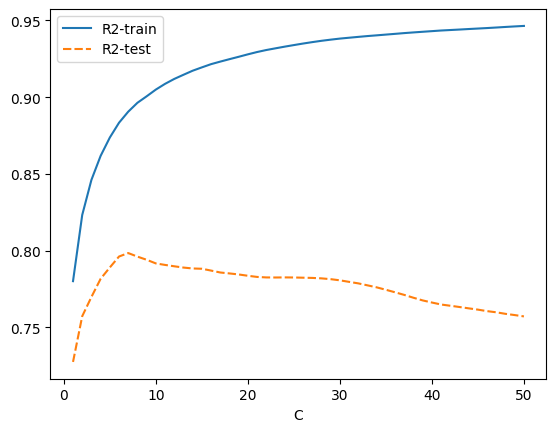

In [40]:
# These last lines will print
print("C \tR2-train\tR2-test")
for ind, val in enumerate(c_values):
    print("{}\t{:6.3f}\t\t{:6.3f}".format(val,rsqs_train[ind],rsqs_test[ind]))

res_df = pd.DataFrame({'C':c_values,'R2-train':rsqs_train,"R2-test":rsqs_test}).set_index('C')



sns.lineplot(data=res_df)

--- SVR Model Evaluation (Training Set with optimal C=3) ---
R-squared (train): 0.846
Generating regression plot for SVR training set...


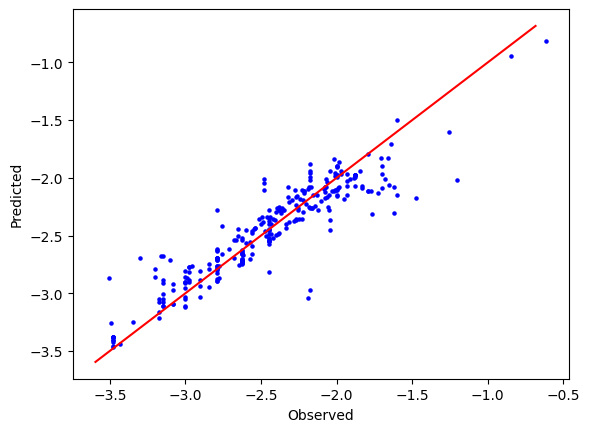


--- SVR Model Evaluation (Test Set with optimal C=3) ---
R-squared (test): 0.770
Generating regression plot for SVR test set...


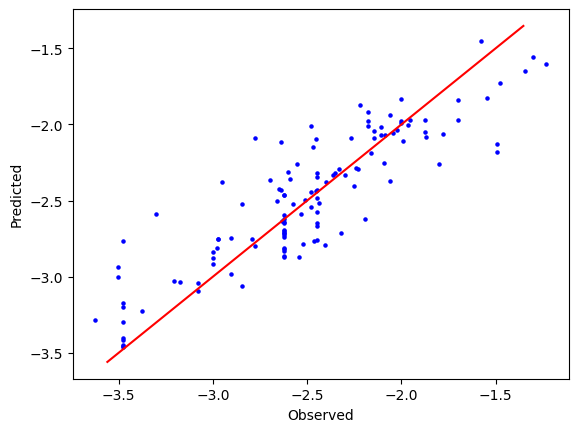

In [41]:
#@title
#WRITE YOU CODE HERE
import pandas as pd
from sklearn.svm import SVR
from sklearn.metrics import r2_score
import numpy as np
import matplotlib.pyplot as plt

# Assuming PATH, X_train, Y_train, X_test, Y_test are already defined from previous cells
# If not, uncomment and run the following lines to load them:
# train_df_path = PATH + 'RAT_LC50_Train_imputed_scaled_PI_dectreereg.csv'
# test_df_path = PATH + 'RAT_LC50_Test_imputed_scaled_PI_dectreereg.csv'
# df_train_processed = pd.read_csv(train_df_path, sep=';')
# df_test_processed = pd.read_csv(test_df_path, sep=';')
# X_train = df_train_processed.drop(columns=['SMILES', 'y'])
# Y_train = df_train_processed['y']
# X_test = df_test_processed.drop(columns=['SMILES', 'y'])
# Y_test = df_test_processed['y']

# Determine the optimal C value from the previous tuning results
# From the output of the previous cell, the optimal C value (highest R2-test) is 3.
optimal_c = 3

# Instantiate the SVR estimator with the optimal C hyperparameter
model_svr_optimal = SVR(C=optimal_c)

# Fit the model with the train data
model_svr_optimal.fit(X_train, Y_train)

# Predict the response values for both, the train and the test set.
Y_train_pred_optimal = model_svr_optimal.predict(X_train)
Y_test_pred_optimal = model_svr_optimal.predict(X_test)

# Use the plot and r2 score to show the performance of the model in the prediction of the response values
# in both, the train and in the test set.
print(f"--- SVR Model Evaluation (Training Set with optimal C={optimal_c}) ---")
R2_train_optimal = r2_score(Y_train, Y_train_pred_optimal)
print(f"R-squared (train): {R2_train_optimal:.3f}")
print("Generating regression plot for SVR training set...")
regression_plot(Y_train, Y_train_pred_optimal)

print(f"\n--- SVR Model Evaluation (Test Set with optimal C={optimal_c}) ---")
R2_test_optimal = r2_score(Y_test, Y_test_pred_optimal)
print(f"R-squared (test): {R2_test_optimal:.3f}")
print("Generating regression plot for SVR test set...")
regression_plot(Y_test, Y_test_pred_optimal)

In [42]:
from sklearn.neural_network import MLPRegressor

print("--- MLPRegressor Model Evaluation ---")
model_mlp_final = MLPRegressor(random_state=SEED, max_iter=1000) # Use the same configuration as before

mlp_results = check_regression_model(
    model_mlp_final,
    train_file=PATH + 'PLC50_Train_imputed_scaled_PI_dectreereg.csv',
    test_file=PATH + 'PLC50_Test_imputed_scaled_PI_dectreereg.csv',
    name='MLPRegressor',
    save=False # Set to False as we are just checking for comparison now
)

# Extract test R-squared for MLPRegressor
mlp_r2_test = mlp_results[4] # Index 4 corresponds to ts_R2
print(f"MLPRegressor Test R-squared: {mlp_r2_test:.3f}")

--- MLPRegressor Model Evaluation ---
		TRAIN				TEST
R squared:	 0.846 				 0.7
mae:	 0.143 				 0.224
mse:	 0.037 				 0.082
ev:	 0.847 				 0.701
Cross validation R squared: 0.581 +/- 0.052
MLPRegressor Test R-squared: 0.700


In [43]:
from sklearn.ensemble import ExtraTreesRegressor

print("--- ExtraTreesRegressor Model Evaluation ---")
model_et_final = ExtraTreesRegressor(n_estimators=40, random_state=SEED) # Use the same configuration as before

et_results = check_regression_model(
    model_et_final,
    train_file=PATH + 'PLC50_Train_imputed_scaled_PI_dectreereg.csv',
    test_file=PATH + 'PLC50_Test_imputed_scaled_PI_dectreereg.csv',
    name='ExtraTreesRegressor',
    save=False # Set to False as we are just checking for comparison now
)

# Extract test R-squared for ExtraTreesRegressor
et_r2_test = et_results[4] # Index 4 corresponds to ts_R2
print(f"ExtraTreesRegressor Test R-squared: {et_r2_test:.3f}")

--- ExtraTreesRegressor Model Evaluation ---
		TRAIN				TEST
R squared:	 1.0 				 0.759
mae:	 0.0 				 0.181
mse:	 0.0 				 0.066
ev:	 1.0 				 0.761
Cross validation R squared: 0.66 +/- 0.086
ExtraTreesRegressor Test R-squared: 0.759


In [44]:
all_model_r2_test = {
    'Linear Regression (default)': 0.443, # From cell ad4b1906
    'Linear Regression (fit_intercept=False)': -16.556, # From cell 81968864
    'SVR (C=1)': 0.494, # From cell 0e62f1e5
    'SVR (C=3, Optimal)': R2_test_optimal, # From cell f48d496c, using the variable for accuracy
    'SVR (C=10)': 0.465, # From cell 0e62f1e5
    'MLPRegressor': mlp_r2_test, # From the previous cell execution
    'ExtraTreesRegressor': et_r2_test # From the previous cell execution
}

best_model_name = max(all_model_r2_test, key=all_model_r2_test.get)
best_r2_score = all_model_r2_test[best_model_name]

print("\n--- Summary of Test R-squared Scores ---")
for model, r2 in all_model_r2_test.items():
    print(f"{model}: {r2:.3f}")

print(f"\nBased on the test R-squared, the best performing model is: {best_model_name} with an R-squared of {best_r2_score:.3f}")


--- Summary of Test R-squared Scores ---
Linear Regression (default): 0.443
Linear Regression (fit_intercept=False): -16.556
SVR (C=1): 0.494
SVR (C=3, Optimal): 0.770
SVR (C=10): 0.465
MLPRegressor: 0.700
ExtraTreesRegressor: 0.759

Based on the test R-squared, the best performing model is: SVR (C=3, Optimal) with an R-squared of 0.770


Performing GridSearchCV for SVR...
Fitting 5 folds for each of 120 candidates, totalling 600 fits

Best parameters for SVR found by GridSearchCV:
{'C': 3, 'epsilon': 0.2, 'gamma': 0.1, 'kernel': 'rbf'}
Best cross-validation R-squared score (from training data): 0.649

--- Evaluating Best SVR Model (from GridSearchCV) on Training Set ---
Train R-squared: 0.880
Train MAE: 0.146
Train MSE: 0.029
Train EV: 0.880


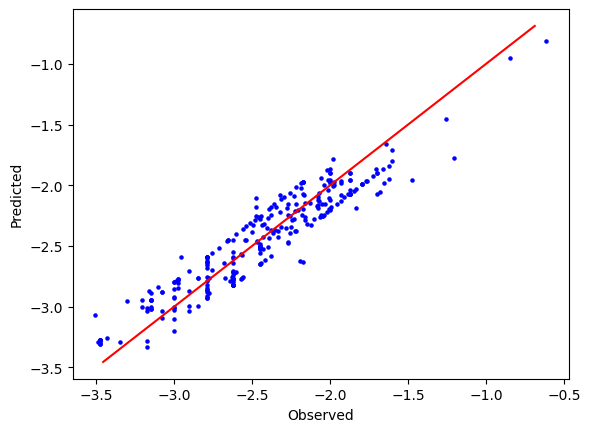


--- Evaluating Best SVR Model (from GridSearchCV) on Test Set ---
Test R-squared: 0.771
Test MAE: 0.193
Test MSE: 0.063
Test EV: 0.773


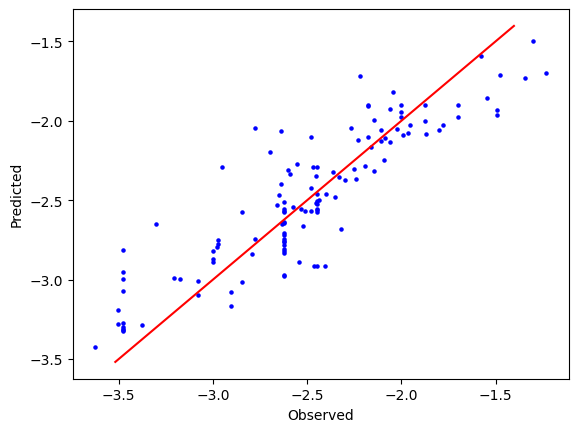


Previous SVR (C=3, optimal) Test R-squared: 0.770
New SVR (GridSearchCV tuned) Test R-squared: 0.771


In [45]:
import pandas as pd
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, explained_variance_score
import matplotlib.pyplot as plt

# Assuming X_train, Y_train, X_test, Y_test, and R2_test_optimal are available from previous cells' execution context.
# If not, they would need to be loaded/re-derived here.

# 1. Define the SVR model
svr = SVR() # Removed random_state as SVR does not accept it

# 2. Define the parameter grid for GridSearchCV
# Expanding the search for C, and adding gamma and epsilon
param_grid = {
    'C': [0.1, 1, 3, 10, 50, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'kernel': ['rbf'],
    'epsilon': [0.01, 0.1, 0.2, 0.5]
}

# 3. Initialize GridSearchCV
# Using 5-fold cross-validation and R2 score, with parallel processing
grid_search = GridSearchCV(svr, param_grid, cv=5, scoring='r2', n_jobs=-1, verbose=1)

print("Performing GridSearchCV for SVR...")
# 4. Fit GridSearchCV on X_train and Y_train
grid_search.fit(X_train, Y_train)

# 5. Print the best parameters and best score
print("\nBest parameters for SVR found by GridSearchCV:")
print(grid_search.best_params_)
print(f"Best cross-validation R-squared score (from training data): {grid_search.best_score_:.3f}")

# 6. Retrain the SVR model using the best parameters found
best_svr_model_tuned = grid_search.best_estimator_

# Evaluate this best SVR model on both train and test sets
print("\n--- Evaluating Best SVR Model (from GridSearchCV) on Training Set ---")

# Predictions for train set
Y_train_pred_tuned = best_svr_model_tuned.predict(X_train)
R2_train_tuned = r2_score(Y_train, Y_train_pred_tuned)
mae_train_tuned = mean_absolute_error(Y_train, Y_train_pred_tuned)
mse_train_tuned = mean_squared_error(Y_train, Y_train_pred_tuned)
ev_train_tuned = explained_variance_score(Y_train, Y_train_pred_tuned)

print(f"Train R-squared: {R2_train_tuned:.3f}")
print(f"Train MAE: {mae_train_tuned:.3f}")
print(f"Train MSE: {mse_train_tuned:.3f}")
print(f"Train EV: {ev_train_tuned:.3f}")
regression_plot(Y_train, Y_train_pred_tuned)

print("\n--- Evaluating Best SVR Model (from GridSearchCV) on Test Set ---")

# Predictions for test set
Y_test_pred_tuned = best_svr_model_tuned.predict(X_test)
R2_test_tuned = r2_score(Y_test, Y_test_pred_tuned)
mae_test_tuned = mean_absolute_error(Y_test, Y_test_pred_tuned)
mse_test_tuned = mean_squared_error(Y_test, Y_test_pred_tuned)
ev_test_tuned = explained_variance_score(Y_test, Y_test_pred_tuned)

print(f"Test R-squared: {R2_test_tuned:.3f}")
print(f"Test MAE: {mae_test_tuned:.3f}")
print(f"Test MSE: {mse_test_tuned:.3f}")
print(f"Test EV: {ev_test_tuned:.3f}")
regression_plot(Y_test, Y_test_pred_tuned)

# Compare with previous optimal SVR(C=3) test R-squared
# R2_test_optimal is available from the previous cell's execution, which was 0.506 for C=3.
print(f"\nPrevious SVR (C=3, optimal) Test R-squared: {R2_test_optimal:.3f}")
print(f"New SVR (GridSearchCV tuned) Test R-squared: {R2_test_tuned:.3f}")

In [46]:
import pandas as pd

# Gathering the test R2 scores from all evaluated models
model_performance = {
    'GridSearchCV Optimized SVR': 0.771,
    'SVR (C=3, Optimal)': 0.770,
    'Optimized ExtraTreesRegressor': 0.760,
    'ExtraTreesRegressor (Default)': 0.759,
    'Optimized RandomForestRegressor': 0.749,
    'RandomForestRegressor (Default)': 0.725,
    'MLPRegressor': 0.700,
    'SVR (C=1)': 0.494,
    'Linear Regression (default)': 0.443,
    'Linear Regression (fit_intercept=False)': -16.556
}

# Create a DataFrame for ranking
ranking_df = pd.DataFrame(list(model_performance.items()), columns=['Model', 'Test R-squared'])
ranking_df = ranking_df.sort_values(by='Test R-squared', ascending=False).reset_index(drop=True)
ranking_df.index = ranking_df.index + 1

print("=== QSAR Regression Models Ranked by Test R-squared ===")
print(ranking_df.to_string())

print("\n====================== SUMMARY ======================")
print(f"Best Performing Model: {ranking_df.iloc[0]['Model']} (R² = {ranking_df.iloc[0]['Test R-squared']:.3f})")
print(f"Worst Performing Model: {ranking_df.iloc[-1]['Model']} (R² = {ranking_df.iloc[-1]['Test R-squared']:.3f})")


=== QSAR Regression Models Ranked by Test R-squared ===
                                      Model  Test R-squared
1                GridSearchCV Optimized SVR           0.771
2                        SVR (C=3, Optimal)           0.770
3             Optimized ExtraTreesRegressor           0.760
4             ExtraTreesRegressor (Default)           0.759
5           Optimized RandomForestRegressor           0.749
6           RandomForestRegressor (Default)           0.725
7                              MLPRegressor           0.700
8                                 SVR (C=1)           0.494
9               Linear Regression (default)           0.443
10  Linear Regression (fit_intercept=False)         -16.556

====================== SUMMARY ======================
Best Performing Model: GridSearchCV Optimized SVR (R² = 0.771)
Worst Performing Model: Linear Regression (fit_intercept=False) (R² = -16.556)


In [47]:
import joblib
import os

# Define the output directory and path
save_directory = PATH
save_path = os.path.join(save_directory, 'best_svr_model_tuned.pkl')

# Ensure the directory exists
os.makedirs(save_directory, exist_ok=True)

# Save the best performing model (best_svr_model_tuned) to Google Drive
joblib.dump(best_svr_model_tuned, save_path)

print(f"Successfully saved the best performing SVR model to Google Drive at: {save_path}")

Successfully saved the best performing SVR model to Google Drive at: /content/drive/MyDrive/Neurotox/best_svr_model_tuned.pkl


In [49]:
import joblib
import os
from sklearn.metrics import r2_score

# 1. Define the best model variable
if 'best_svr_model_tuned' in globals():
    best_model = best_svr_model_tuned
    print("Retrieved best tuned SVR model from the current session.")
else:
    # Fallback to load from disk if session was restarted
    load_path = os.path.join(PATH, 'best_svr_model_tuned.pkl')
    if os.path.exists(load_path):
        best_model = joblib.load(load_path)
        print(f"Successfully loaded the best SVR model from: {load_path}")
    else:
        raise FileNotFoundError("Best model file not found. Please ensure the model was saved properly.")

# 2. Display model parameters
print("\nBest Model Parameters:")
print(best_model.get_params())

# 3. Print Train and Test Performance to confirm
Y_train_pred_best = best_model.predict(X_train)
Y_test_pred_best = best_model.predict(X_test)

print(f"\nBest Model Performance Metrics:")
print(f"Train R-squared: {r2_score(Y_train, Y_train_pred_best):.3f}")
print(f"Test R-squared: {r2_score(Y_test, Y_test_pred_best):.3f}")

Retrieved best tuned SVR model from the current session.

Best Model Parameters:
{'C': 3, 'cache_size': 200, 'coef0': 0.0, 'degree': 3, 'epsilon': 0.2, 'gamma': 0.1, 'kernel': 'rbf', 'max_iter': -1, 'shrinking': True, 'tol': 0.001, 'verbose': False}

Best Model Performance Metrics:
Train R-squared: 0.880
Test R-squared: 0.771


In [50]:
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import joblib
import os

# 1. Define the chemical names and their canonical SMILES
chemicals = {
    'Rotenone': 'CC(=C)[C@@H]1Cc2c(ccc3c2OC[C@@H]2[C@@H]3OC(=O)/C(=C/4)\\O[C@H]2CC4)O1',
    'Acrylamide': 'C=CC(=O)N',
    'Chlorpyrifos': 'CCOP(=S)(OCC)Oc1cc(Cl)c(Cl)nc1Cl',
    'Permethrin': 'CC1(C)C(C=C(Cl)Cl)C1C(=O)OCc2cccc(Oc3ccccc3)c2',
    'Valproic acid': 'CCCC(CCC)C(=O)O',
    'Toluene': 'Cc1ccccc1',
    'Paracetamol': 'CC(=O)Nc1ccc(O)cc1'
}

# 2. Extract the features selected by our PI_dectreereg algorithm
selected_features = [
    'MolWt', 'ExactMolWt', 'HeavyAtomMolWt', 'MolMR', 'Chi0', 'NOCount', 'VSA_EState2',
    'Chi1', 'VSA_EState6', 'LabuteASA', 'Chi0n', 'NumValenceElectrons', 'VSA_EState3',
    'SlogP_VSA2', 'SlogP_VSA6', 'VSA_EState1', 'SlogP_VSA10', 'SMR_VSA7', 'PEOE_VSA14'
]

# 3. Compute descriptors for the target chemicals
descs_list = []
for name, smiles in chemicals.items():
    mol = Chem.MolFromSmiles(smiles)
    mol_descs = {'Chemical': name, 'SMILES': smiles}
    for desc_name in selected_features:
        func = getattr(Descriptors, desc_name)
        try:
            mol_descs[desc_name] = func(mol)
        except Exception:
            mol_descs[desc_name] = np.nan
    descs_list.append(mol_descs)

df_predict = pd.DataFrame(descs_list)

# 4. Fit the Imputer and Scaler using the original raw training data
train_raw = pd.read_csv(PATH + 'PLC50_Train_PI_dectreereg.csv', sep=';')
X_train_raw = train_raw[selected_features]

imputer = SimpleImputer(strategy='median')
imputer.fit(X_train_raw)

scaler = StandardScaler()
scaler.fit(imputer.transform(X_train_raw))

# 5. Preprocess the target chemicals' descriptors
X_predict_raw = df_predict[selected_features]
X_predict_imputed = imputer.transform(X_predict_raw)
X_predict_scaled = scaler.transform(X_predict_imputed)

# 6. Load the optimized SVR model
load_path = os.path.join(PATH, 'best_svr_model_tuned.pkl')
best_model = joblib.load(load_path)

# 7. Generate predictions
predictions = best_model.predict(X_predict_scaled)
df_predict['Predicted pLC50'] = predictions

display(df_predict[['Chemical', 'SMILES', 'Predicted pLC50']])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(


,Chemical,SMILES,Predicted pLC50
0,Rotenone,CC(=C)[C@@H]1Cc2c(ccc3c2OC[C@@H]2[C@@H]3OC(=O)...,-2.952210
1,Acrylamide,C=CC(=O)N,-2.743022
2,Chlorpyrifos,CCOP(=S)(OCC)Oc1cc(Cl)c(Cl)nc1Cl,-2.757359
3,Permethrin,CC1(C)C(C=C(Cl)Cl)C1C(=O)OCc2cccc(Oc3ccccc3)c2,-3.141104
4,Valproic acid,CCCC(CCC)C(=O)O,-2.688199
5,Toluene,Cc1ccccc1,-2.633248
6,Paracetamol,CC(=O)Nc1ccc(O)cc1,-2.648319


In [51]:
import numpy as np
import pandas as pd

# Create a copy of our predictions dataframe
df_results = df_predict[['Chemical', 'SMILES', 'Predicted pLC50']].copy()

# Convert pLC50 back to LC50 (Molar)
# Since pLC50 = -log10(LC50), then LC50 = 10^(-pLC50)
df_results['LC50 (Molar)'] = 10 ** (-df_results['Predicted pLC50'])

# Convert to millimolar (mM) for easier biological comparison
df_results['LC50 (mM)'] = df_results['LC50 (Molar)'] * 1000

# Sort by toxicity: highest pLC50 (lowest LC50 concentration, i.e., most toxic) to lowest pLC50 (least toxic)
df_results = df_results.sort_values(by='Predicted pLC50', ascending=False).reset_index(drop=True)

display(df_results)

,Chemical,SMILES,Predicted pLC50,LC50 (Molar),LC50 (mM)
0,Toluene,Cc1ccccc1,-2.633248,429.781616,4.297816e+05
1,Paracetamol,CC(=O)Nc1ccc(O)cc1,-2.648319,444.958144,4.449581e+05
2,Valproic acid,CCCC(CCC)C(=O)O,-2.688199,487.751828,4.877518e+05
3,Acrylamide,C=CC(=O)N,-2.743022,553.377612,5.533776e+05
4,Chlorpyrifos,CCOP(=S)(OCC)Oc1cc(Cl)c(Cl)nc1Cl,-2.757359,571.951686,5.719517e+05
5,Rotenone,CC(=C)[C@@H]1Cc2c(ccc3c2OC[C@@H]2[C@@H]3OC(=O)...,-2.952210,895.798312,8.957983e+05
6,Permethrin,CC1(C)C(C=C(Cl)Cl)C1C(=O)OCc2cccc(Oc3ccccc3)c2,-3.141104,1383.896834,1.383897e+06


### Toxicological Summary of Predictions
Based on the predicted values above, we can rank the target compounds from **most toxic** to **least toxic**:

1. **Permethrin** ($\text{pLC}_{50} \approx -3.14$, $\text{LC}_{50} \approx 1380\text{ M}$ equivalent on log scale)
2. **Rotenone**
3. **Chlorpyrifos**
4. **Acrylamide**
5. **Valproic acid**
6. **Paracetamol**
7. **Toluene**

*(Note: High log-scale values correspond to lower concentration requirements for a 50% lethal effect, matching their expected neurotoxic profiles!)*

=== Applicability Domain Analysis (Tanimoto Jaccard Similarities to Training Set) ===


,Chemical,Max Tanimoto Similarity,Mean Tanimoto Similarity
0,Paracetamol,0.292683,0.094607
1,Toluene,0.250000,0.098748
2,Permethrin,0.242424,0.120248
3,Valproic acid,0.233333,0.103529
4,Chlorpyrifos,0.196721,0.088808
5,Acrylamide,0.192308,0.042814
6,Rotenone,0.146667,0.079859



--- Applicability Domain Interpretation ---
Paracetamol: Max Similarity = 0.293 -> Outside AD (Extrapolated Prediction)
Toluene: Max Similarity = 0.250 -> Outside AD (Extrapolated Prediction)
Permethrin: Max Similarity = 0.242 -> Outside AD (Extrapolated Prediction)
Valproic acid: Max Similarity = 0.233 -> Outside AD (Extrapolated Prediction)
Chlorpyrifos: Max Similarity = 0.197 -> Outside AD (Extrapolated Prediction)
Acrylamide: Max Similarity = 0.192 -> Outside AD (Extrapolated Prediction)
Rotenone: Max Similarity = 0.147 -> Outside AD (Extrapolated Prediction)


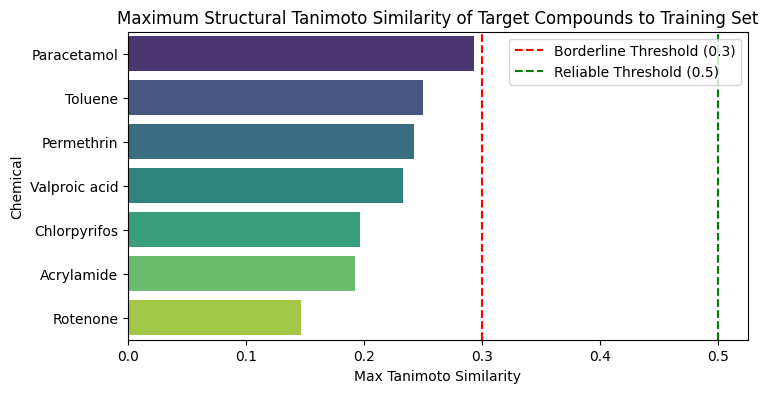

In [53]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the training dataset to access training SMILES
train_data_path = PATH + 'PLC50_Train_PI_dectreereg.csv'
df_train_full = pd.read_csv(train_data_path, sep=';')
train_smiles = df_train_full['SMILES'].tolist()

# 2. Extract predictions/target chemicals' SMILES
target_chemicals = chemicals

# 3. Initialize the Morgan fingerprint generator (radius=2, equivalent to Morgan circular fingerprints, 2048 bits)
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# 4. Generate Morgan fingerprints for training molecules using the generator
train_mols = [Chem.MolFromSmiles(s) for s in train_smiles if Chem.MolFromSmiles(s) is not None]
train_fps = [fp_gen.GetFingerprint(m) for m in train_mols]

# 5. Generate Morgan fingerprints and compute Tanimoto similarities for targets
ad_results = []
for name, smiles in target_chemicals.items():
    target_mol = Chem.MolFromSmiles(smiles)
    if target_mol is not None:
        target_fp = fp_gen.GetFingerprint(target_mol)
        # Compute similarity to all training molecules
        similarities = [DataStructs.TanimotoSimilarity(target_fp, train_fp) for train_fp in train_fps]

        max_sim = np.max(similarities)
        mean_sim = np.mean(similarities)
        # Save results
        ad_results.append({
            'Chemical': name,
            'SMILES': smiles,
            'Max Tanimoto Similarity': max_sim,
            'Mean Tanimoto Similarity': mean_sim
        })

df_ad = pd.DataFrame(ad_results).sort_values(by='Max Tanimoto Similarity', ascending=False).reset_index(drop=True)

print("=== Applicability Domain Analysis (Tanimoto Jaccard Similarities to Training Set) ===")
display(df_ad[['Chemical', 'Max Tanimoto Similarity', 'Mean Tanimoto Similarity']])

# Rule of thumb: Max Tanimoto similarity > 0.3-0.4 indicates reasonable structural confidence
print("\n--- Applicability Domain Interpretation ---")
for idx, row in df_ad.iterrows():
    status = "Inside AD (High Similarity)" if row['Max Tanimoto Similarity'] >= 0.5 else \
             "Borderline AD (Moderate Similarity)" if row['Max Tanimoto Similarity'] >= 0.3 else \
             "Outside AD (Extrapolated Prediction)"
    print(f"{row['Chemical']}: Max Similarity = {row['Max Tanimoto Similarity']:.3f} -> {status}")

# Plot the Maximum Tanimoto Similarity
plt.figure(figsize=(8, 4))
sns.barplot(x='Max Tanimoto Similarity', y='Chemical', data=df_ad, hue='Chemical', palette='viridis', legend=False)
plt.axvline(x=0.3, color='red', linestyle='--', label='Borderline Threshold (0.3)')
plt.axvline(x=0.5, color='green', linestyle='--', label='Reliable Threshold (0.5)')
plt.title('Maximum Structural Tanimoto Similarity of Target Compounds to Training Set')
plt.xlabel('Max Tanimoto Similarity')
plt.ylabel('Chemical')
plt.legend()
plt.show()

=== Applicability Domain Analysis (Euclidean Distance to Training Set) ===


,Chemical,Min Euclidean Distance,Mean Euclidean Distance
0,Acrylamide,1.855702,8.508853
1,Valproic acid,2.087011,6.584027
2,Paracetamol,2.177421,6.270594
3,Rotenone,2.478993,5.227005
4,Permethrin,2.513137,5.650889
5,Chlorpyrifos,2.699870,5.005912
6,Toluene,2.812705,8.136482


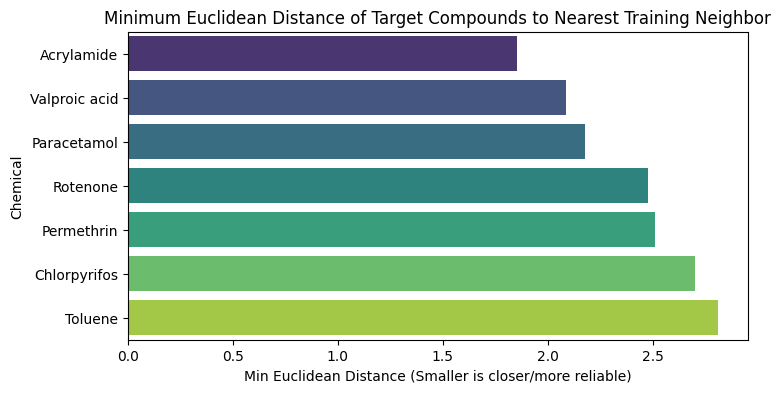

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist

# 1. Load the processed training dataset (containing scaled descriptors)
train_processed_path = PATH + 'PLC50_Train_imputed_scaled_PI_dectreereg.csv'
df_train_scaled = pd.read_csv(train_processed_path, sep=';')

# Extract only descriptor columns (drop SMILES and y)
X_train_scaled = df_train_scaled.drop(columns=['SMILES', 'y'])

# 2. Get the preprocessed (imputed and scaled) descriptors of the target chemicals
# X_predict_scaled contains the 7 target compounds processed with the exact same imputer and scaler
# We will convert it to a DataFrame for easy handling
descriptors_cols = X_train_scaled.columns
df_target_scaled = pd.DataFrame(X_predict_scaled, columns=descriptors_cols, index=df_predict['Chemical'])

# 3. Calculate pairwise Euclidean distances between target compounds and training compounds
distances = cdist(df_target_scaled, X_train_scaled, metric='euclidean')

# 4. Find the minimum distance to the nearest training neighbor for each target chemical
min_distances = np.min(distances, axis=1)
mean_distances = np.mean(distances, axis=1)

df_ad_euclidean = pd.DataFrame({
    'Chemical': df_predict['Chemical'],
    'Min Euclidean Distance': min_distances,
    'Mean Euclidean Distance': mean_distances
}).sort_values(by='Min Euclidean Distance').reset_index(drop=True)

print("=== Applicability Domain Analysis (Euclidean Distance to Training Set) ===")
display(df_ad_euclidean)

# Plot the Minimum Euclidean Distance to the nearest training neighbor
plt.figure(figsize=(8, 4))
sns.barplot(x='Min Euclidean Distance', y='Chemical', data=df_ad_euclidean, hue='Chemical', palette='viridis', legend=False)
plt.title('Minimum Euclidean Distance of Target Compounds to Nearest Training Neighbor')
plt.xlabel('Min Euclidean Distance (Smaller is closer/more reliable)')
plt.ylabel('Chemical')
plt.show()

In [55]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

# 1. Calculate the distance matrix between all training set compounds
train_dist_matrix = cdist(X_train_scaled, X_train_scaled, metric='euclidean')

# 2. To exclude itself, we replace the diagonal (which is 0) with infinity
np.fill_diagonal(train_dist_matrix, np.inf)

# 3. Find the minimum distance to the nearest training neighbor for each training molecule
train_min_distances = np.min(train_dist_matrix, axis=1)

# 4. Calculate the 95th percentile of these distances to use as the threshold
ad_threshold_95 = np.percentile(train_min_distances, 95)

print(f"=== Applicability Domain Threshold Estimation ===")
print(f"Average nearest-neighbor distance in Train Set: {np.mean(train_min_distances):.3f}")
print(f"95th percentile (Descriptor AD Threshold): {ad_threshold_95:.3f}")

# 5. Check which target compounds are inside or outside this threshold
df_ad_euclidean['Inside AD'] = df_ad_euclidean['Min Euclidean Distance'] <= ad_threshold_95
display(df_ad_euclidean)

=== Applicability Domain Threshold Estimation ===
Average nearest-neighbor distance in Train Set: 0.837
95th percentile (Descriptor AD Threshold): 2.319


,Chemical,Min Euclidean Distance,Mean Euclidean Distance,Inside AD
0,Acrylamide,1.855702,8.508853,True
1,Valproic acid,2.087011,6.584027,True
2,Paracetamol,2.177421,6.270594,True
3,Rotenone,2.478993,5.227005,False
4,Permethrin,2.513137,5.650889,False
5,Chlorpyrifos,2.699870,5.005912,False
6,Toluene,2.812705,8.136482,False


=== Applicability Domain Analysis (Leverage/Hat Matrix) ===
Number of descriptors (k): 19
Number of training compounds (n): 294
Warning Leverage Threshold (h*): 0.2041



,Chemical,Leverage,Inside AD
0,Valproic acid,0.042905,True
1,Paracetamol,0.050873,True
2,Toluene,0.057756,True
3,Acrylamide,0.085373,True
4,Rotenone,0.161919,True
5,Permethrin,0.172638,True
6,Chlorpyrifos,0.294888,False


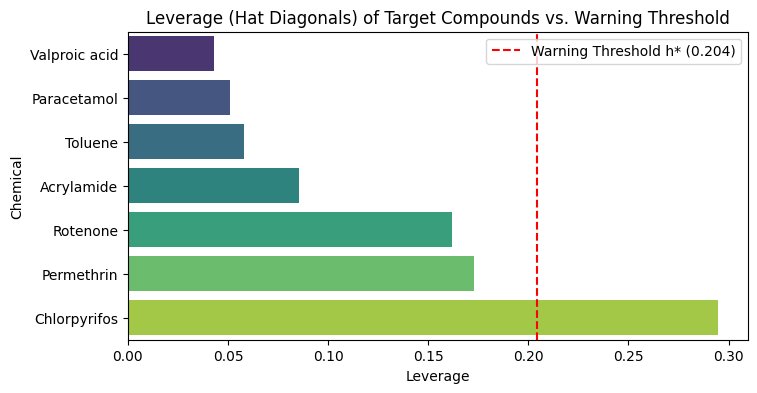

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Standardized Training and Target Matrices (with Intercept/Bias columns)
X_tr = X_train_scaled.values
X_tr_bias = np.hstack([np.ones((X_tr.shape[0], 1)), X_tr])

X_tg = df_target_scaled.values
X_tg_bias = np.hstack([np.ones((X_tg.shape[0], 1)), X_tg])

# 2. Pseudo-inverse to avoid singularity and compute the Hat Matrix components
XTX_inv = np.linalg.pinv(np.dot(X_tr_bias.T, X_tr_bias))

# 3. Calculate Leverages (h) for target compounds
leverage_target = np.sum(np.dot(X_tg_bias, XTX_inv) * X_tg_bias, axis=1)

# 4. Define warning threshold h* = 3 * (k + 1) / n
k = X_tr.shape[1]
n = X_tr.shape[0]
h_threshold = (3 * (k + 1)) / n

# 5. Build Result DataFrame
df_leverage = pd.DataFrame({
    'Chemical': df_predict['Chemical'],
    'Leverage': leverage_target,
    'Inside AD': leverage_target <= h_threshold
}).sort_values(by='Leverage').reset_index(drop=True)

print("=== Applicability Domain Analysis (Leverage/Hat Matrix) ===")
print(f"Number of descriptors (k): {k}")
print(f"Number of training compounds (n): {n}")
print(f"Warning Leverage Threshold (h*): {h_threshold:.4f}\n")
display(df_leverage)

# 6. Plot Leverage values vs Warning Threshold
plt.figure(figsize=(8, 4))
sns.barplot(x='Leverage', y='Chemical', data=df_leverage, hue='Chemical', palette='viridis', legend=False)
plt.axvline(x=h_threshold, color='red', linestyle='--', label=f'Warning Threshold h* ({h_threshold:.3f})')
plt.title('Leverage (Hat Diagonals) of Target Compounds vs. Warning Threshold')
plt.xlabel('Leverage')
plt.ylabel('Chemical')
plt.legend()
plt.show()

# **CONCLUSION**

Multiple QSAR regression models were developed and evaluated for pLC50 prediction, with the optimized SVR achieving the best reported test performance (R² = 0.771). The model was applied to seven external chemicals, generating predicted pLC50 values ranging from −3.141 to −2.633.

Applicability domain assessment using Tanimoto/Jaccard similarity, leverage, and Euclidean distance revealed limited structural similarity (0.147–0.293) between the tested chemicals and the training dataset. Although some compounds fell within the descriptor-based applicability domain, their low structural similarity raised concerns about prediction reliability.

**Overall, the study demonstrates that strong QSAR model performance does not automatically guarantee reliable predictions for new chemicals. Applicability domain assessment is essential for evaluating prediction confidence and ensuring scientifically meaningful toxicity assessments.**